# FluxSprout: single-cell metabolic modeling of zebrafish vascular sprouting

**Purpose.** This notebook runs the FluxSprout analysis end to end from the raw GEO matrices
(GSM6138416, GSM6138417) and the distributed Zebrafish-GEM, and produces every number, figure, table and
supplementary item of the article.

**Structure**
1. Setup and engine validation
2. Single-cell QC (Fig. 1)
3. Lineage and endothelial-state atlas (Fig. 1)
4. Tip versus cycling ISV cells: a cell-cycle confound (Fig. 2)
5. Marker-level hypothesis tests with cell-cycle adjustment (Fig. 3)
6. Genome-scale model audit: objective, limiting nutrient, OXPHOS/PPase factorial, flux caps (Fig. 4)
7. Thermodynamically infeasible cycles (TIC) audit (Fig. 4)
8. Expression-constrained flux (E-Flux) with binding bounds; metacell-level flux tests (Fig. 5)
9. Context-specific model ensemble and knockout screen with full lineage controls (Fig. 6)
10. Mechanism of the all-lineage calls (Fig. 6)
11. Medium sensitivity of candidate calls
12. Literature phenotype table (Table 6) recomputed with loop correction
13. Export of result tables and figures
14. Supplementary figures and tables (Figs. S1 to S4, Tables S1 to S5, Supplementary Data S1)

**Runtime.** Heavy steps (context-model ensemble, knockout screens) are cached in `results/`.
Set `RECOMPUTE = True` to rebuild everything (about 4 to 6 hours on a 2-core machine; the knockout screens dominate).
With the cache present the notebook runs in about 15 to 25 minutes. The COBRApy-readable SBML models in `models/` are written by `fluxsprout/export_models.py`.

In [1]:
import os, sys, json, time, pickle, warnings
warnings.filterwarnings('ignore')
HERE = os.path.abspath('.')
sys.path.insert(0, os.path.join(HERE, 'fluxsprout'))
os.makedirs('cache', exist_ok=True); os.makedirs('results', exist_ok=True); os.makedirs('figures', exist_ok=True)
RECOMPUTE = False          # True: rebuild all cached heavy results

import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt, matplotlib as mpl
import scanpy as sc, anndata as ad, cobra
from figstyle import *
setup()
sc.settings.verbosity = 0
print('scanpy', sc.__version__, '| cobra', cobra.__version__, '| numpy', np.__version__)

def cached(path):
    return os.path.exists(path) and not RECOMPUTE

scanpy 1.12.4 | cobra 0.32.1 | numpy 2.5.3


## 1. Engine validation
Constraint-based steps use `hlp.py`, a thin HiGHS (highspy) engine: about 80 times faster than COBRApy+GLPK on this
11k-reaction network (0.03 s per warm-started knockout LP), which is what makes full knockout screens over a model
ensemble feasible. Before use it is checked against COBRApy on the *E. coli* core model.

In [2]:
from cobra.io import load_model as _lm
from cobra.flux_analysis import pfba as _pfba, flux_variability_analysis as _fva, single_gene_deletion as _sgd, find_blocked_reactions as _fbr
from hlp import Net, fastcore, can_carry
_m = _lm('textbook'); _n = Net(_m)
chk = {}
chk['FBA |diff|'] = abs(_n.fba() - _m.slim_optimize())
_lo, _hi = _n.fva(frac=0.9); _f = _fva(_m, fraction_of_optimum=0.9)
chk['FVA max |diff|'] = max(abs(_lo[i] - _f.minimum.iloc[i]) + abs(_hi[i] - _f.maximum.iloc[i]) for i in range(_n.n))
_w, _ko = _n.gene_screen(); _d = _sgd(_m); _d['g'] = _d.ids.apply(lambda s: list(s)[0]); _d = _d.set_index('g').growth / _m.slim_optimize()
chk['gene KO max |diff|'] = max(abs(_ko.get(g, 1) - _d[g]) for g in _d.index if not np.isnan(_d[g]))
_c = can_carry(_n); chk['blocked reactions identical'] = sorted(set(_n.ids) - {_n.ids[i] for i in _c}) == sorted(_fbr(_m))
_v = _n.pfba(); chk['pFBA total flux rel. diff'] = abs(np.abs(_v).sum() - _pfba(_m).fluxes.abs().sum()) / _pfba(_m).fluxes.abs().sum()
pd.Series(chk)

FBA |diff|                          0.0
FVA max |diff|                      0.0
gene KO max |diff|                  0.0
blocked reactions identical        True
pFBA total flux rel. diff      0.000096
dtype: object

## 2. Single-cell QC
Per-sample filters exactly as in Methods 2.1: at least 500 genes, at least 1,000 UMIs, under 5% mitochondrial reads,
upper-tail 5-MAD log-count outliers, Scrublet score above 0.25 (Scanpy's implementation), genes in at least 3 cells.

In [3]:
RAW = {'vascular': 'GSM6138416_filtered_feature_bc_matrix_GFP+mCherry+.h5',
       'non-vascular': 'GSM6138417_filtered_feature_bc_matrix_GFP+mCherry-.h5'}
if True:   # fast (a few minutes); recomputed every run so no large .h5ad cache is needed
    ads = []
    for lab, f in RAW.items():
        x = sc.read_10x_h5(f); x.var_names_make_unique(); x.obs['sample'] = lab
        x.obs_names = [f'{lab[:1]}_{b}' for b in x.obs_names]
        x.var['mt'] = x.var_names.str.startswith('mt-'); x.var['ribo'] = x.var_names.str.match(r'^rp[sl]\d')
        sc.pp.calculate_qc_metrics(x, qc_vars=['mt', 'ribo'], inplace=True, percent_top=None, log1p=True)
        sc.pp.scrublet(x, random_state=0)
        lc = np.log1p(x.obs.total_counts); med = np.median(lc); mad = np.median(np.abs(lc - med))
        x.obs['f_lowgenes'] = x.obs.n_genes_by_counts < 500; x.obs['f_lowumi'] = x.obs.total_counts < 1000
        x.obs['f_mito'] = x.obs.pct_counts_mt >= 5; x.obs['f_mad'] = lc > med + 5 * 1.4826 * mad
        x.obs['f_doublet'] = x.obs.doublet_score > 0.25
        x.obs['keep'] = ~x.obs[['f_lowgenes', 'f_lowumi', 'f_mito', 'f_mad', 'f_doublet']].any(axis=1)
        ads.append(x)
    raw = ad.concat(ads, join='outer', fill_value=0)
    qc_all = raw.obs[['sample', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'doublet_score', 'keep',
                      'f_lowgenes', 'f_lowumi', 'f_mito', 'f_mad', 'f_doublet']].copy()
    qc_all.to_csv('results/qc_all_droplets.csv')
    a = raw[raw.obs.keep].copy(); sc.pp.filter_genes(a, min_cells=3); a.layers['counts'] = a.X.copy()
qsum = qc_all.groupby('sample').agg(raw=('keep', 'size'), low_genes_or_umi=('f_lowgenes', lambda s: int((s | qc_all.loc[s.index, 'f_lowumi']).sum())),
                                   high_mito=('f_mito', 'sum'), mad_outlier=('f_mad', 'sum'), doublet=('f_doublet', 'sum'), kept=('keep', 'sum'))
print('QC cells', a.n_obs, '| genes', a.n_vars); qsum

QC cells 10090 | genes 24205


,raw,low_genes_or_umi,high_mito,mad_outlier,doublet,kept
sample,,,,,,
non-vascular,6990,1443,1049,0,85,5024
vascular,6390,813,872,0,43,5066


**Note.** The 5-MAD multiplet filter removes zero droplets in both libraries, and the Fig. 1D
"low genes" bar (813 / 1,443) is the union of the gene and UMI filters.

## 3. Lineage and endothelial-state atlas
Normalization, batch-aware Seurat-v3 HVGs (sort marker, mitochondrial, ribosomal and hemoglobin genes excluded),
PCA (50), Leiden 1.0, marker-based lineage labels. Low-quality clusters match the four described in Methods 2.2
(eGFP/keratin, fabp3/hmgb2b, ribosomal/pmaip1, apoc1/mfap4/hemoglobin). Endothelial + HE/EMP cells are
re-embedded and subclustered (Leiden 1.4); states are assigned from marker and hox (cranial vs trunk) expression.

In [4]:
LINEAGE = {**{c: 'Endothelial' for c in [1, 2, 3, 4, 6, 7, 8, 9, 13, 14, 19, 21]}, 18: 'HE/EMP',
           **{c: 'Erythroid' for c in [11, 12, 22, 24, 30, 34]}, 26: 'Macrophage', 15: 'Myeloid', 10: 'Muscle',
           17: 'Neural prog.', 25: 'Neuron', 29: 'Fibroblast', 16: 'Mesenchyme', 20: 'Mesenchyme', 28: 'Post. mes.',
           23: 'Epithelium', 27: 'Periderm', 31: 'Xantho.', 35: 'LPM/cardiac', 0: 'lowQ', 5: 'lowQ', 32: 'lowQ', 33: 'lowQ'}
STATE = {'11': 'aDA', '12': 'aDA', '5': 'aCran', '9': 'aCran', '2': 'aTrunk_mixed', '13': 'ISV_tip', '6': 'ISV_tip',
         '17': 'ISV_cyc', '1': 'cranV', '18': 'cranV', '3': 'cranV_cyc', '7': 'vPCV', '16': 'vPCV_cyc', '0': 'vCV',
         '15': 'vCV', '21': 'vCV', '10': 'angioblast', '4': 'angioblast', '20': 'angioblast_cyc', '19': 'endocard',
         '14': 'HE_EMP', '8': 'unresolved'}
S_GENES = ['mcm5','pcna','tyms','fen1','mcm2','mcm4','rrm1','ung','gins2','mcm6','cdca7','dtl','prim1','uhrf1','mlf1ip','hells','rfc2','rpa2','nasp','rad51ap1','gmnn','wdr76','slbp','ccne2','ubr7','pold3','msh2','atad2','rad51','rrm2','cdc45','cdc6','exo1','tipin','dscc1','blm','casp8ap2','usp1','clspn','pola1','chaf1b','brip1','e2f8']
G2M_GENES = ['hmgb2','cdk1','nusap1','ube2c','birc5','tpx2','top2a','ndc80','cks2','nuf2','cks1b','mki67','tmpo','cenpf','tacc3','fam64a','smc4','ccnb2','ckap2l','ckap2','aurkb','bub1','kif11','anp32e','tubb4b','gtse1','kif20b','hjurp','cdca3','hn1','cdc20','ttk','cdc25c','kif2c','rangap1','ncapd2','dlgap5','cdca2','cdca8','ect2','kif23','hmmr','aurka','psrc1','anln','lbr','ckap5','cenpe','ctcf','nek2','g2e3','gas2l3','cbx5','cenpa']

sc.pp.normalize_total(a, target_sum=1e4); sc.pp.log1p(a); a.raw = a
sc.pp.highly_variable_genes(a, n_top_genes=3000, flavor='seurat_v3', layer='counts', batch_key='sample')
a.var.loc[a.var_names.str.match(r'^(mt-|rp[sl]\d|hb[ab]|hbae|hbbe|hbaa|eGFP|mCherry)'), 'highly_variable'] = False
b = a[:, a.var.highly_variable].copy(); sc.pp.scale(b, max_value=10); sc.tl.pca(b, n_comps=50, random_state=0); a.obsm['X_pca'] = b.obsm['X_pca']
zf = lambda gs: [v for g in gs for v in a.var_names if v in (g, g + 'a', g + 'b', g + '.1')]
a.uns['cc_genes'] = {'S': zf(S_GENES), 'G2M': zf(G2M_GENES)}
if os.path.exists('results/cell_annotations.csv'):
    # stored labels from the reference run (Leiden numbering can change between library versions)
    ann = pd.read_csv('results/cell_annotations.csv', index_col=0)
    a = a[ann.index].copy()
    for c_ in ['leiden', 'lineage', 'phase', 'S_score', 'G2M_score']: a.obs[c_] = ann[c_].values
    a.obs['lineage'] = a.obs.lineage.astype('category'); a.obsm['X_umap'] = ann[['umap1', 'umap2']].values
    e = a[ann.state.notna().values].copy(); e.obs['state'] = ann.loc[e.obs_names, 'state'].astype('category').values
    e.obs['l1.4'] = ann.loc[e.obs_names, 'ec_cluster'].astype(int).astype(str).values; e.obsm['X_umap'] = ann.loc[e.obs_names, ['ec_umap1', 'ec_umap2']].values
else:
    sc.pp.neighbors(a, n_pcs=50, random_state=0); sc.tl.umap(a, random_state=0)
    sc.tl.leiden(a, resolution=1.0, random_state=0, flavor='igraph', n_iterations=-1, directed=False)
    a.obs['lineage'] = a.obs.leiden.astype(int).map(LINEAGE).astype('category')   # check marker table below if versions differ
    a = a[a.obs.lineage != 'lowQ'].copy()
    sc.tl.score_genes_cell_cycle(a, s_genes=a.uns['cc_genes']['S'], g2m_genes=a.uns['cc_genes']['G2M'], random_state=0)
    e = a[a.obs.lineage.isin(['Endothelial', 'HE/EMP'])].copy()
    sc.pp.highly_variable_genes(e, n_top_genes=2000, flavor='seurat_v3', layer='counts')
    e.var.loc[e.var_names.str.match(r'^(mt-|rp[sl]\d|hb[ab]|eGFP)'), 'highly_variable'] = False
    b = e[:, e.var.highly_variable].copy(); sc.pp.scale(b, max_value=10); sc.tl.pca(b, n_comps=30, random_state=0)
    e.obsm['X_pca'] = b.obsm['X_pca']; sc.pp.neighbors(e, n_pcs=30, random_state=0); sc.tl.umap(e, random_state=0)
    sc.tl.leiden(e, resolution=1.4, key_added='l1.4', random_state=0, flavor='igraph', n_iterations=-1, directed=False)
    e.obs['state'] = e.obs['l1.4'].map(STATE).astype('category')
print('annotated cells', a.n_obs, '| EC+HE cells', e.n_obs)
print(a.obs.lineage.value_counts().to_dict())
print(e.obs.state.value_counts().to_dict())

annotated cells 8709 | EC+HE cells 3727
{'Endothelial': 3596, 'Erythroid': 2536, 'Neural prog.': 431, 'Macrophage': 391, 'Mesenchyme': 320, 'Epithelium': 301, 'Fibroblast': 263, 'Post. mes.': 211, 'Muscle': 170, 'HE/EMP': 131, 'Periderm': 128, 'Myeloid': 119, 'Neuron': 69, 'Xantho.': 24, 'LPM/cardiac': 19}
{'vCV': 443, 'aDA': 430, 'angioblast': 428, 'cranV': 364, 'ISV_tip': 362, 'vPCV': 292, 'unresolved': 222, 'vPCV_cyc': 202, 'aCran': 193, 'ISV_cyc': 185, 'cranV_cyc': 180, 'angioblast_cyc': 169, 'aTrunk_mixed': 110, 'HE_EMP': 107, 'endocard': 40}


### Figure 1. QC and atlas

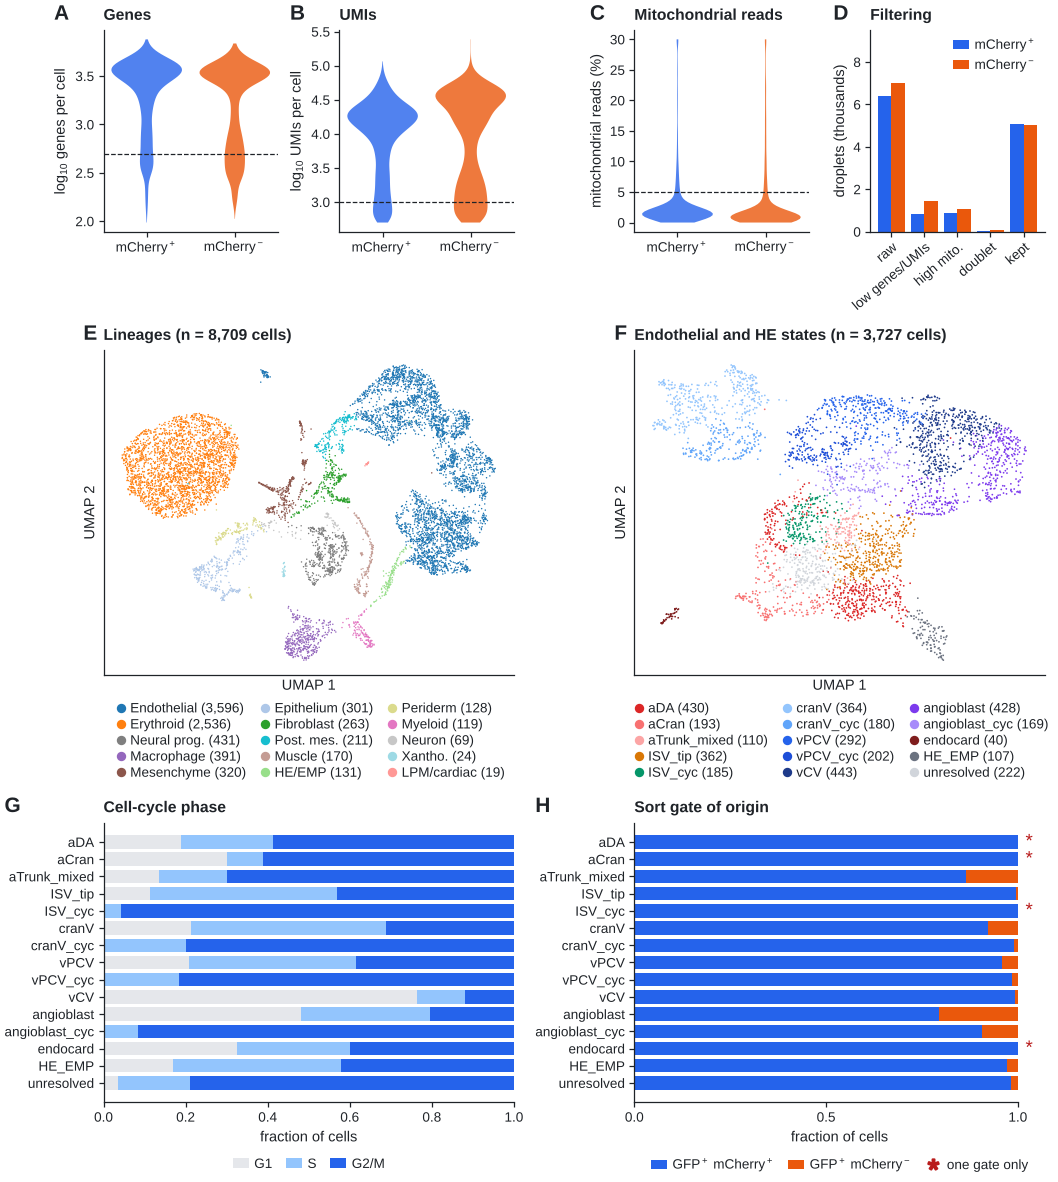

In [5]:
setup()
fig = new_figure(200)
gs = fig.add_gridspec(3, 4, height_ratios=[0.9, 1.45, 1.25])
GATE = {'vascular': ('mCherry$^+$', C['accent']), 'non-vascular': ('mCherry$^-$', C['orange'])}
for k, (col, lab, logy, thr) in enumerate([('n_genes_by_counts', 'genes per cell', True, 500), ('total_counts', 'UMIs per cell', True, 1000),
                                           ('pct_counts_mt', 'mitochondrial reads (%)', False, 5)]):
    ax = fig.add_subplot(gs[0, k])
    data = [np.log10(qc_all.loc[qc_all['sample'] == s, col] + 1) if logy else qc_all.loc[qc_all['sample'] == s, col].clip(upper=30) for s in GATE]
    vp = ax.violinplot(data, showextrema=False, widths=0.8)
    for b_, s in zip(vp['bodies'], GATE): b_.set_facecolor(GATE[s][1]); b_.set_alpha(0.8); b_.set_edgecolor('none')
    ax.axhline(np.log10(thr) if logy else thr, ls='--', lw=0.6, color=INK)
    ax.set_xticks([1, 2]); ax.set_xticklabels([GATE[s][0] for s in GATE]); ax.set_ylabel(('log$_{10}$ ' if logy else '') + lab)
    ax.set_title(['Genes', 'UMIs', 'Mitochondrial reads'][k]); panel(ax, 'ABC'[k])
ax = fig.add_subplot(gs[0, 3])
steps = ['raw', 'low_genes_or_umi', 'high_mito', 'doublet', 'kept']; xx = np.arange(len(steps))
for j, s in enumerate(GATE):
    ax.bar(xx + (j - 0.5) * 0.4, qsum.loc[s, steps] / 1000, 0.4, color=GATE[s][1], label=GATE[s][0])
ax.set_xticks(xx); ax.set_xticklabels(['raw', 'low genes/UMIs', 'high mito.', 'doublet', 'kept'], rotation=40, ha='right', rotation_mode='anchor')
ax.set_ylabel('droplets (thousands)'); ax.set_ylim(0, 9.5); ax.legend(loc='upper right', ncol=1)
ax.set_title('Filtering'); panel(ax, 'D')

ax = fig.add_subplot(gs[1, :2])
U = a.obsm['X_umap']; labs = a.obs.lineage.astype(str)
pal = dict(zip(sorted(labs.unique()), plt.cm.tab20(np.linspace(0, 1, labs.nunique()))))
ax.scatter(U[:, 0], U[:, 1], s=0.5, c=[pal[l] for l in labs], rasterized=True, linewidths=0)
order_l = sorted(pal, key=lambda x: -(labs == x).sum())
hd = [mpl.lines.Line2D([], [], marker='o', ls='', ms=3.5, color=pal[l], label=f'{l} ({(labs == l).sum():,})') for l in order_l]
ax.legend(handles=hd, loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=3, handletextpad=0.1, labelspacing=0.25, columnspacing=0.8)
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel('UMAP 1', labelpad=2); ax.set_ylabel('UMAP 2')
ax.set_title(f'Lineages (n = {a.n_obs:,} cells)'); panel(ax, 'E')
ax = fig.add_subplot(gs[1, 2:])
U = e.obsm['X_umap']; st = e.obs.state.astype(str)
ax.scatter(U[:, 0], U[:, 1], s=0.7, c=[STATE_COL[s] for s in st], rasterized=True, linewidths=0)
order = [s for s in STATE_COL if s in set(st)]
hd = [mpl.lines.Line2D([], [], marker='o', ls='', ms=3.5, color=STATE_COL[s], label=f'{s} ({(st == s).sum():,})') for s in order]
ax.legend(handles=hd, loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=3, handletextpad=0.1, labelspacing=0.25, columnspacing=0.8)
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel('UMAP 1', labelpad=2); ax.set_ylabel('UMAP 2')
ax.set_title(f'Endothelial and HE states (n = {e.n_obs:,} cells)'); panel(ax, 'F')

ax = fig.add_subplot(gs[2, :2])
ph = pd.crosstab(e.obs.state, e.obs.phase, normalize='index').loc[order, ['G1', 'S', 'G2M']]
left = np.zeros(len(order))
for p_, c_ in zip(['G1', 'S', 'G2M'], ['#e5e7eb', '#93c5fd', '#2563eb']):
    ax.barh(range(len(order)), ph[p_], left=left, color=c_, label=p_.replace('G2M', 'G2/M'), height=0.78); left += ph[p_].values
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel('fraction of cells')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.17)); ax.set_title('Cell-cycle phase'); panel(ax, 'G')
ax = fig.add_subplot(gs[2, 2:])
gate = pd.crosstab(e.obs.state, e.obs['sample'], normalize='index').loc[order]
ax.barh(range(len(order)), gate['vascular'], color=C['accent'], height=0.78, label='GFP$^+$ mCherry$^+$')
ax.barh(range(len(order)), gate['non-vascular'], left=gate['vascular'], color=C['orange'], height=0.78, label='GFP$^+$ mCherry$^-$')
for i, s in enumerate(order):
    if gate.loc[s, 'non-vascular'] == 0: ax.text(1.02, i, '*', va='center', ha='left', fontsize=9, color=C['bad'])
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis(); ax.set_xlim(0, 1.07); ax.set_xticks([0, 0.5, 1])
ax.spines['bottom'].set_bounds(0, 1); ax.set_xlabel('fraction of cells')
hd = ax.get_legend_handles_labels()[0] + [mpl.lines.Line2D([], [], marker='$*$', ls='', ms=5, color=C['bad'], label='one gate only')]
ax.legend(handles=hd, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.17)); ax.set_title('Sort gate of origin'); panel(ax, 'H')
save(fig, 'Fig1_QC_atlas'); plt.show()

## 4. Tip versus cycling ISV cells: the split is mostly cell-cycle phase
Both ISV clusters carry the same sprouting program (*esm1*, *hlx1*, *apln*, *aplnrb*, *flt1*). The test:
(i) are the differentially expressed genes cell-cycle genes; (ii) does the separation survive regressing out S and
G2/M scores; (iii) do pathway scores differ once phase and depth are controlled.

In [6]:
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import silhouette_score, adjusted_rand_score
isv = e[e.obs.state.isin(['ISV_tip', 'ISV_cyc'])].copy()
ccg = set(a.uns['cc_genes']['S']) | set(a.uns['cc_genes']['G2M'])
sc.tl.rank_genes_groups(isv, 'state', groups=['ISV_cyc'], reference='ISV_tip', method='wilcoxon', n_genes=isv.n_vars)
de = sc.get.rank_genes_groups_df(isv, 'ISV_cyc')
de_sig = de[(de.pvals_adj < 0.05) & (de.logfoldchanges.abs() > 0.5)]
Xe = e[:, [g for g in de_sig.names if g in e.var_names]].X.toarray()
r_g2m = pd.Series([np.corrcoef(Xe[:, j], e.obs.G2M_score)[0, 1] for j in range(Xe.shape[1])], index=de_sig.names).fillna(0)
r_s = pd.Series([np.corrcoef(Xe[:, j], e.obs.S_score)[0, 1] for j in range(Xe.shape[1])], index=de_sig.names).fillna(0)
de_sig = de_sig.assign(r_cycle=np.maximum(r_g2m.abs().values, r_s.abs().values))
top_up = de_sig[de_sig.logfoldchanges > 0].head(200)
print(f"DE (q<0.05, |log2FC|>0.5): {int((de_sig.logfoldchanges>0).sum())} up, {int((de_sig.logfoldchanges<0).sum())} down in ISV_cyc")
print('fraction of top-200 up genes correlated with a cycle score (|r|>0.3):', round((top_up.r_cycle > 0.3).mean(), 2))
# regress out cycle scores and recompute separation
b = isv.copy(); sc.pp.highly_variable_genes(b, n_top_genes=1500, flavor='seurat_v3', layer='counts')
b.var.loc[b.var_names.isin(ccg) | b.var_names.str.match(r'^(mt-|rp[sl])'), 'highly_variable'] = False
b = b[:, b.var.highly_variable].copy(); b_raw = b.copy()
sc.pp.scale(b_raw, max_value=10); sc.tl.pca(b_raw, n_comps=20, random_state=0)
sc.pp.regress_out(b, ['S_score', 'G2M_score']); sc.pp.scale(b, max_value=10); sc.tl.pca(b, n_comps=20, random_state=0)
sil = {'before': silhouette_score(b_raw.obsm['X_pca'], b_raw.obs.state), 'after cycle regression': silhouette_score(b.obsm['X_pca'], b.obs.state)}
sc.pp.neighbors(b, random_state=0); ari = {}
for r in [0.2, 0.4, 0.6]:
    sc.tl.leiden(b, resolution=r, random_state=0, flavor='igraph', n_iterations=-1, directed=False, key_added='lr')
    ari[r] = adjusted_rand_score(b.obs.lr, b.obs.state)
print('silhouette', {k: round(v, 3) for k, v in sil.items()}, '| ARI of cycle-regressed clusters with tip/cyc labels', {k: round(v, 2) for k, v in ari.items()})
de_sig.to_csv('results/TableS_ISVcyc_vs_tip_DE.csv', index=False)

DE (q<0.05, |log2FC|>0.5): 449 up, 72 down in ISV_cyc
fraction of top-200 up genes correlated with a cycle score (|r|>0.3): 0.9


silhouette {'before': 0.18, 'after cycle regression': 0.057} | ARI of cycle-regressed clusters with tip/cyc labels {0.2: 0.31, 0.4: 0.14, 0.6: 0.12}


Pathway marker panels are built reproducibly from Zebrafish-GEM subsystems (genes of the subsystem's reactions,
detected in at least 5% of endothelial cells; the four pyrophosphatase reactions excluded from OXPHOS).

In [7]:
m0 = cobra.io.read_sbml_model('Zebrafish-GEM.xml') if not os.path.exists('cache/zgem.pkl') else pickle.load(open('cache/zgem.pkl', 'rb'))
if not os.path.exists('cache/zgem.pkl'): pickle.dump(m0, open('cache/zgem.pkl', 'wb'))
SUBS = {'glycolysis': ['Glycolysis / Gluconeogenesis'], 'TCA': ['Tricarboxylic acid cycle and glyoxylate/dicarboxylate metabolism'],
        'OXPHOS': ['Oxidative phosphorylation'], 'FAO': sorted(s for s in {r.subsystem for r in m0.reactions} if s.startswith('Beta oxidation') and 'mitochondrial' in s),
        'nucleotide': ['Purine metabolism', 'Pyrimidine metabolism'], 'serine_1C': ['Glycine, serine and threonine metabolism', 'Folate metabolism'],
        'carnitine': ['Carnitine shuttle (mitochondrial)'], 'PPP': ['Pentose phosphate pathway', 'Pentose Phosphate Pathway']}
PPI4 = {'MAR03975', 'MAR03977', 'MAR03979', 'MAR06912'}
ee = e[e.obs.state != 'unresolved'].copy()
det = np.asarray((ee.raw.X > 0).mean(0)).ravel(); detected = set(ee.raw.var_names[det >= 0.05])
panels = {k: sorted({g.id for r in m0.reactions if r.subsystem in ss and r.id not in PPI4 for g in r.genes} & detected) for k, ss in SUBS.items()}
for k, g in panels.items(): sc.tl.score_genes(ee, g, score_name=k, random_state=0, use_raw=True)
ee.obs['logUMI'] = np.log10(ee.obs.total_counts)
print({k: len(v) for k, v in panels.items()})
iso = ee.obs[ee.obs.state.isin(['ISV_tip', 'ISV_cyc'])].copy(); iso['cyc'] = (iso.state == 'ISV_cyc').astype(int)
rows = []
for k in panels:
    f0 = smf.ols(f'{k} ~ cyc', iso).fit(cov_type='HC3'); f1 = smf.ols(f'{k} ~ cyc + S_score + G2M_score + logUMI', iso).fit(cov_type='HC3')
    rows.append(dict(pathway=k, raw=f0.params['cyc'], raw_lo=f0.conf_int().loc['cyc', 0], raw_hi=f0.conf_int().loc['cyc', 1], raw_p=f0.pvalues['cyc'],
                     adj=f1.params['cyc'], adj_lo=f1.conf_int().loc['cyc', 0], adj_hi=f1.conf_int().loc['cyc', 1], adj_p=f1.pvalues['cyc']))
isv_path = pd.DataFrame(rows); isv_path['raw_q'] = multipletests(isv_path.raw_p, method='fdr_bh')[1]; isv_path['adj_q'] = multipletests(isv_path.adj_p, method='fdr_bh')[1]
isv_path.to_csv('results/TableS_ISVcyc_vs_tip_pathways.csv', index=False); isv_path.round(4)

{'glycolysis': 42, 'TCA': 33, 'OXPHOS': 85, 'FAO': 19, 'nucleotide': 82, 'serine_1C': 30, 'carnitine': 4, 'PPP': 14}


,pathway,raw,raw_lo,raw_hi,raw_p,adj,adj_lo,adj_hi,adj_p,raw_q,adj_q
0,glycolysis,-0.0049,-0.0238,0.0140,0.6085,-0.0075,-0.0357,0.0207,0.6038,0.6085,0.6901
1,TCA,-0.0057,-0.0178,0.0065,0.3612,-0.0139,-0.0351,0.0074,0.2022,0.4816,0.3880
2,OXPHOS,-0.0531,-0.0777,-0.0285,0.0000,-0.0483,-0.0840,-0.0125,0.0081,0.0001,0.0324
3,FAO,-0.0281,-0.0399,-0.0162,0.0000,-0.0194,-0.0403,0.0015,0.0691,0.0000,0.1843
4,nucleotide,-0.0046,-0.0119,0.0026,0.2068,0.0187,0.0075,0.0300,0.0011,0.3309,0.0088
5,serine_1C,0.0027,-0.0062,0.0116,0.5557,0.0085,-0.0077,0.0248,0.3041,0.6085,0.4055
6,carnitine,-0.0322,-0.0486,-0.0158,0.0001,-0.0200,-0.0535,0.0135,0.2425,0.0003,0.3880
7,PPP,-0.0181,-0.0296,-0.0067,0.0019,0.0020,-0.0177,0.0217,0.8435,0.0039,0.8435


### Figure 2. The "tip/stalk" contrast is an S versus G2/M contrast within one ISV program

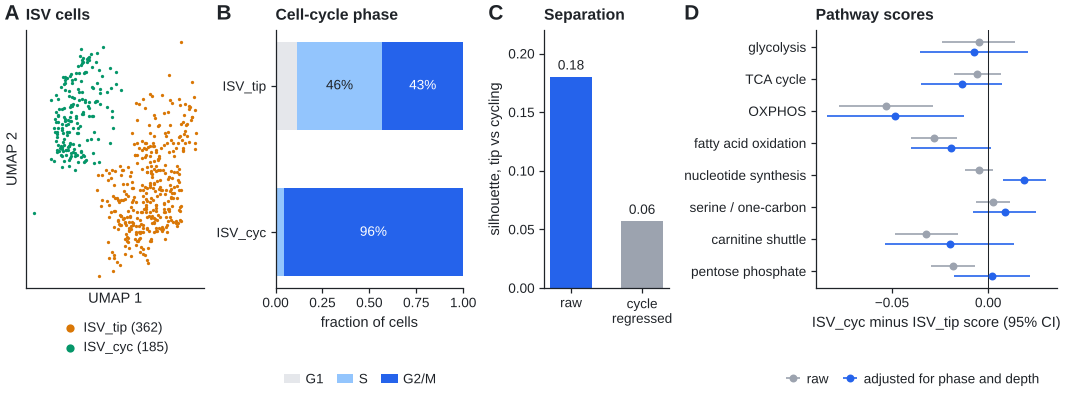

In [8]:
setup()
fig = new_figure(66)
gs = fig.add_gridspec(1, 4, width_ratios=[1.0, 1.05, 0.7, 1.35])
ax = fig.add_subplot(gs[0]); Ui = isv.obsm['X_umap']
for s in ['ISV_tip', 'ISV_cyc']:
    sel = (isv.obs.state == s).values; ax.scatter(Ui[sel, 0], Ui[sel, 1], s=2.5, c=STATE_COL[s], label=f'{s} ({sel.sum()})', linewidths=0, rasterized=True)
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel('UMAP 1', labelpad=2); ax.set_ylabel('UMAP 2')
ax.legend(markerscale=2.5, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=1); ax.set_title('ISV cells'); panel(ax, 'A')
ax = fig.add_subplot(gs[1])
ph = pd.crosstab(isv.obs.state, isv.obs.phase, normalize='index').loc[['ISV_tip', 'ISV_cyc'], ['G1', 'S', 'G2M']]
left = np.zeros(2)
for p_, c_ in zip(['G1', 'S', 'G2M'], ['#e5e7eb', '#93c5fd', '#2563eb']):
    ax.barh([0, 1], ph[p_], left=left, color=c_, label=p_.replace('G2M', 'G2/M'), height=0.6)
    for i in range(2):
        if ph[p_].iloc[i] > 0.15: ax.text(left[i] + ph[p_].iloc[i] / 2, i, f'{ph[p_].iloc[i]:.0%}', ha='center', va='center', fontsize=6.5, color='white' if p_ == 'G2M' else INK)
    left += ph[p_].values
ax.set_yticks([0, 1]); ax.set_yticklabels(['ISV_tip', 'ISV_cyc']); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel('fraction of cells')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.45, -0.3)); ax.set_title('Cell-cycle phase'); panel(ax, 'B')
ax = fig.add_subplot(gs[2])
vals = [sil['before'], sil['after cycle regression']]
ax.bar([0, 1], vals, color=[C['accent'], C['no']], width=0.6)
ax.set_xticks([0, 1]); ax.set_xticklabels(['raw', 'cycle\nregressed']); ax.set_ylabel('silhouette, tip vs cycling'); ax.set_ylim(0, 0.22); ax.set_yticks([0, 0.05, 0.10, 0.15, 0.20])
for i, v in enumerate(vals): ax.text(i, v + 0.006, f'{v:.2f}', ha='center', fontsize=6.5)
ax.set_title('Separation'); panel(ax, 'C')
ax = fig.add_subplot(gs[3]); yy = np.arange(len(isv_path))
PN = {'glycolysis': 'glycolysis', 'TCA': 'TCA cycle', 'OXPHOS': 'OXPHOS', 'FAO': 'fatty acid oxidation', 'nucleotide': 'nucleotide synthesis',
      'serine_1C': 'serine / one-carbon', 'carnitine': 'carnitine shuttle', 'PPP': 'pentose phosphate'}
ax.errorbar(isv_path.raw, yy - 0.16, xerr=[isv_path.raw - isv_path.raw_lo, isv_path.raw_hi - isv_path.raw], fmt='o', ms=2.8, color=C['no'], lw=0.8, label='raw')
ax.errorbar(isv_path.adj, yy + 0.16, xerr=[isv_path.adj - isv_path.adj_lo, isv_path.adj_hi - isv_path.adj], fmt='o', ms=2.8, color=C['accent'], lw=0.8, label='adjusted for phase and depth')
ax.axvline(0, color=INK, lw=0.5); ax.set_yticks(yy); ax.set_yticklabels([PN.get(p, p) for p in isv_path.pathway]); ax.invert_yaxis()
ax.set_xlabel('ISV_cyc minus ISV_tip score (95% CI)'); ax.legend(loc='upper center', bbox_to_anchor=(0.4, -0.3), ncol=2)
ax.set_title('Pathway scores'); panel(ax, 'D')
save(fig, 'Fig2_tip_vs_cycling_ISV'); plt.show()

## 5. Marker-level hypothesis tests, raw and adjusted for cell-cycle phase and depth
Compartments: tip = ISV_tip; cycling = ISV_cyc + vPCV_cyc + cranV_cyc + angioblast_cyc;
arterial = aDA + aCran; venous = vPCV + vCV + cranV. Each claim: one-sided Mann-Whitney
and an OLS model `score ~ focal + S + G2M + log UMI` with HC3 errors; BH correction across claims.

In [9]:
COMP = {'ISV_tip': 'tip', 'ISV_cyc': 'cycling', 'vPCV_cyc': 'cycling', 'angioblast_cyc': 'cycling', 'cranV_cyc': 'cycling',
        'aDA': 'arterial', 'aCran': 'arterial', 'vPCV': 'venous', 'vCV': 'venous', 'cranV': 'venous'}
from scipy.stats import mannwhitneyu
ce = ee.obs.assign(comp=ee.obs.state.map(COMP).astype(object)); ce = ce[ce.comp.notna()]
CLAIMS = [('tip', 'glycolysis', 'Tip cells are most glycolytic (De Bock 2013)'), ('arterial', 'glycolysis', 'Arterial lineage most glycolytic'),
          ('cycling', 'nucleotide', 'Proliferating EC: nucleotide synthesis (Schoors 2015)'), ('cycling', 'serine_1C', 'Proliferating EC: serine/1C (Vandekeere 2018)'),
          ('venous', 'FAO', 'Quiescent/venous EC: FAO (Kalucka 2018)'), ('cycling', 'TCA', 'Cycling EC: TCA (conventional-screen prediction)'),
          ('tip', 'OXPHOS', 'Tip cells: OXPHOS (corrected panel)'), ('cycling', 'carnitine', 'Cycling EC: carnitine shuttle (SLC25A20 axis)')]
rng = np.random.default_rng(0); rows = []
for focal, path, label in CLAIMS:
    x = ce.loc[ce.comp == focal, path].values; y = ce.loc[ce.comp != focal, path].values
    boots = [rng.choice(x, len(x)).mean() - rng.choice(y, len(y)).mean() for _ in range(2000)]
    d = ce.assign(focal=(ce.comp == focal).astype(int)); f = smf.ols(f'{path} ~ focal + S_score + G2M_score + logUMI', d).fit(cov_type='HC3')
    p1 = f.pvalues['focal'] / 2 if f.params['focal'] > 0 else 1 - f.pvalues['focal'] / 2
    rows.append(dict(claim=label, focal=focal, pathway=path, n=len(x), diff=x.mean() - y.mean(), lo=np.percentile(boots, 2.5), hi=np.percentile(boots, 97.5),
                     p_mwu=mannwhitneyu(x, y, alternative='greater').pvalue, highest=ce.groupby('comp')[path].mean().idxmax(),
                     adj=f.params['focal'], adj_lo=f.conf_int().loc['focal', 0], adj_hi=f.conf_int().loc['focal', 1], p_adj=p1))
CL = pd.DataFrame(rows); CL['q_mwu'] = multipletests(CL.p_mwu, method='fdr_bh')[1]; CL['q_adj'] = multipletests(CL.p_adj, method='fdr_bh')[1]
CL['verdict_raw'] = np.where((CL.q_mwu < 0.05) & (CL.highest == CL.focal), 'supported', np.where(CL.hi < 0, 'opposite direction', 'not supported'))
hi_adj = {}
for focal, path, label in CLAIMS:   # adjusted group means (residual score after phase + depth) to apply the same 'highest compartment' rule
    rr = smf.ols(f'{path} ~ S_score + G2M_score + logUMI', ce).fit().resid; hi_adj[label] = rr.groupby(ce.comp).mean().idxmax()
CL['highest_adjusted'] = CL.claim.map(hi_adj)
CL['verdict_adjusted'] = np.where((CL.q_adj < 0.05) & (CL.adj > 0) & (CL.highest_adjusted == CL.focal), 'supported', np.where(CL.adj_hi < 0, 'opposite direction', 'not supported'))
CL.to_csv('results/TableS_claims_marker_level.csv', index=False)
CL[['claim', 'n', 'diff', 'q_mwu', 'verdict_raw', 'adj', 'q_adj', 'verdict_adjusted']].round(4)

,claim,n,diff,q_mwu,verdict_raw,adj,q_adj,verdict_adjusted
0,Tip cells are most glycolytic (De Bock 2013),362,0.0345,0.0000,supported,0.0367,0.0000,supported
1,Arterial lineage most glycolytic,623,0.0284,0.0000,not supported,0.0319,0.0000,not supported
2,Proliferating EC: nucleotide synthesis (Schoor...,736,0.0218,0.0000,supported,0.0180,0.0000,supported
3,Proliferating EC: serine/1C (Vandekeere 2018),736,0.0108,0.0000,supported,0.0129,0.0001,supported
4,Quiescent/venous EC: FAO (Kalucka 2018),1099,0.0096,0.0003,supported,0.0032,0.1821,not supported
5,Cycling EC: TCA (conventional-screen prediction),736,-0.0056,1.0000,opposite direction,-0.0073,0.9973,not supported
6,Tip cells: OXPHOS (corrected panel),362,0.0556,0.0000,supported,0.0585,0.0000,supported
7,Cycling EC: carnitine shuttle (SLC25A20 axis),736,-0.0278,1.0000,opposite direction,-0.0153,0.9973,opposite direction


### Figure 3. Marker-level claims before and after phase/depth adjustment

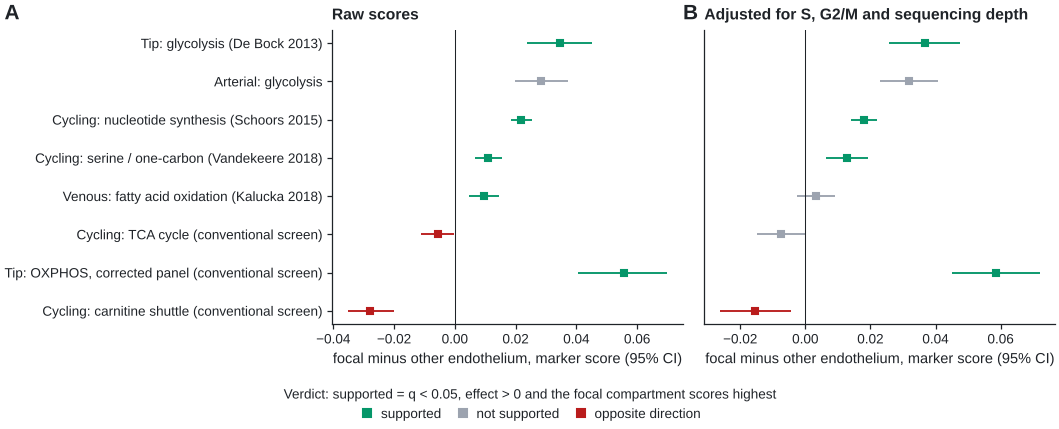

In [10]:
setup()
VC = {'supported': C['ok'], 'not supported': C['no'], 'opposite direction': C['bad']}
NAMES = {'Tip cells are most glycolytic (De Bock 2013)': 'Tip: glycolysis (De Bock 2013)',
         'Arterial lineage most glycolytic': 'Arterial: glycolysis',
         'Proliferating EC: nucleotide synthesis (Schoors 2015)': 'Cycling: nucleotide synthesis (Schoors 2015)',
         'Proliferating EC: serine/1C (Vandekeere 2018)': 'Cycling: serine / one-carbon (Vandekeere 2018)',
         'Quiescent/venous EC: FAO (Kalucka 2018)': 'Venous: fatty acid oxidation (Kalucka 2018)',
         'Cycling EC: TCA (conventional-screen prediction)': 'Cycling: TCA cycle (conventional screen)',
         'Tip cells: OXPHOS (corrected panel)': 'Tip: OXPHOS, corrected panel (conventional screen)',
         'Cycling EC: carnitine shuttle (SLC25A20 axis)': 'Cycling: carnitine shuttle (conventional screen)'}
fig = new_figure(72)
axs = fig.subplots(1, 2, sharey=True)
yy = np.arange(len(CL))
for ax, (est, lo, hi, ver, title) in zip(axs, [('diff', 'lo', 'hi', 'verdict_raw', 'Raw scores'), ('adj', 'adj_lo', 'adj_hi', 'verdict_adjusted', 'Adjusted for S, G2/M and sequencing depth')]):
    for i, r in CL.iterrows():
        ax.errorbar(r[est], i, xerr=[[r[est] - r[lo]], [r[hi] - r[est]]], fmt='s', ms=3.2, color=VC[r[ver]], lw=0.9)
    ax.axvline(0, color=INK, lw=0.5); ax.set_title(title); ax.set_xlabel('focal minus other endothelium, marker score (95% CI)')
axs[0].set_yticks(yy); axs[0].set_yticklabels([NAMES.get(c_, c_) for c_ in CL.claim]); axs[0].invert_yaxis()
axs[1].tick_params(axis='y', length=0)
handles = [mpl.lines.Line2D([], [], marker='s', ls='', ms=4, color=c_, label=k) for k, c_ in VC.items()]
fig.legend(handles=handles, loc='outside lower center', ncol=3, title='Verdict: supported = q < 0.05, effect > 0 and the focal compartment scores highest')
panel(axs[0], 'A'); panel(axs[1], 'B')
save(fig, 'Fig3_marker_claims'); plt.show()

## 6. Genome-scale model audit
### 6.1 Flux consistency, objective and what limits growth
All biomass reactions ship with bounds (0, 0); the model's default objective is MAR00021 (no growth-associated ATP).
MAR13082 (generic human biomass, 45 ATP GAM) needs vitamin B12 (aquacob(III)alamin) and gamma-tocopherol on a defined
medium. Reduced costs at the optimum identify the limiting nutrient.

In [11]:
from fslib import *
from hlp import Net, can_carry, gapfill_support
m = load_model('cache/zgem.pkl')
if cached('cache/ref_medium_consistent.pkl'):
    ref = pickle.load(open('cache/ref_medium_consistent.pkl', 'rb')); cons_ids = json.load(open('results/fastcc_consistent.json'))
else:
    mu_ = m.copy(); set_objective(mu_); apply_medium(mu_, None, unbounded=True)
    n_ = Net(mu_); cons_ids = sorted(n_.ids[i] for i in can_carry(n_)); json.dump(cons_ids, open('results/fastcc_consistent.json', 'w'))
    ref = m.copy(); set_objective(ref); ref.remove_reactions([r for r in ref.reactions if r.id not in set(cons_ids)], remove_orphans=True)
    apply_medium(ref, baseline_medium()); ref.reactions.get_by_id(NGAM).lower_bound = 1.0
    n_ = Net(ref); live = {n_.ids[i] for i in can_carry(n_)} | {r.id for r in ref.exchanges if r.lower_bound < 0}
    ref.remove_reactions([r for r in ref.reactions if r.id not in live], remove_orphans=True); ref.objective = BIOMASS
    pickle.dump(ref, open('cache/ref_medium_consistent.pkl', 'wb'))
print('flux-consistent (open exchanges):', len(cons_ids), '| consistent under yolk-like medium:', len(ref.reactions), 'reactions,', len(ref.genes), 'genes')

lim = []
mc_ = m.copy(); mc_.remove_reactions([r for r in mc_.reactions if r.id not in set(cons_ids)], remove_orphans=True)
for obj in ['MAR13082', 'MAR04413', 'MAR00021']:
    with mc_:
        set_objective(mc_, obj); apply_medium(mc_, baseline_medium()); mc_.reactions.get_by_id(NGAM).lower_bound = 1.0
        mc_.solver = 'glpk'; s = mc_.optimize(); rc = s.reduced_costs
        limiting = {k: round(rc[v], 3) for k, v in EXCH.items() if v in rc.index and abs(rc[v]) > 1e-6}
        p = cobra.flux_analysis.pfba(mc_)   # minimal-flux optimum: the uptake the optimum needs
        lim.append(dict(objective=obj, growth=s.objective_value, glucose_needed_pFBA=-p.fluxes[EXCH['glucose']], O2_needed_pFBA=-p.fluxes[EXCH['O2']],
                        glucose_offered=10, limiting_exchange=limiting))
LIM = pd.DataFrame(lim); LIM.to_csv('results/TableS_objective_limiting_nutrient.csv', index=False); LIM

flux-consistent (open exchanges): 11356 | consistent under yolk-like medium: 9480 reactions, 2170 genes


,objective,growth,glucose_needed_pFBA,O2_needed_pFBA,glucose_offered,limiting_exchange
0,MAR13082,2.035922,10.000000,20.000000,10,{'leucine': -4.072}
1,MAR04413,1.688864,1.042975,9.185015,10,{'lysine': -3.378}
2,MAR00021,0.012658,0.209331,8.105345,10,{'leucine': -0.025}


### 6.2 OXPHOS / pyrophosphatase factorial and ATP-yield audit
Factorial over objective (MAR13082 vs MAR00021) x medium (constrained vs unbounded) x NGAM (0 to 40) x reaction
set (legacy 10, corrected 6, the 4 mislabeled PPases, all 5 PPases). Capacity is titrated relative to each
reaction's flux in the intact optimum.

In [12]:
SETS = {'legacy10': OXPHOS10, 'corrected6': OXPHOS6, 'PPase4': PPI_LEGACY, 'PPase5': PPI_LEGACY + ['MAR07794']}
if cached('results/oxphos_factorial.csv'):
    FAC = pd.read_csv('results/oxphos_factorial.csv')
else:
    rows = []
    for obj in ['MAR13082', 'MAR00021']:
        set_objective(mc_, obj)
        for med in ['constrained', 'unbounded']:
            apply_medium(mc_, baseline_medium(), unbounded=(med == 'unbounded'))
            for ngam in [0, 1, 5, 20, 40]:
                mc_.reactions.get_by_id(NGAM).lower_bound = ngam
                net = Net(mc_, objective=obj); wt, x = net.fba(return_x=True)
                for sname, rs in SETS.items():
                    idx = [net.idx[r] for r in rs if r in net.idx]
                    for cap in [1.0, 0.75, 0.5, 0.25, 0.1, 0.0]:
                        for i in idx:
                            lim_ = abs(x[i]) * cap; net._base().changeColBounds(i, float(max(net.lb[i], -lim_)), float(min(net.ub[i], lim_)))
                        g = net.fba()
                        for i in idx: net._base().changeColBounds(i, float(net.lb[i]), float(net.ub[i]))
                        rows.append(dict(objective=obj, medium=med, NGAM=ngam, set=sname, capacity=cap, growth_rel=g / wt if wt > 1e-9 else np.nan, wt=wt))
    FAC = pd.DataFrame(rows); FAC.to_csv('results/oxphos_factorial.csv', index=False)
FAC[FAC.capacity == 0].pivot_table(index=['objective', 'medium', 'NGAM'], columns='set', values='growth_rel').round(3)

set                         PPase4  PPase5  corrected6  legacy10
objective medium      NGAM                                      
MAR00021  constrained 0      1.000     0.0       0.499     0.499
                      1      1.000     0.0       0.474     0.474
                      5      1.000    -0.0       0.375     0.375
                      20     1.000     0.0       0.004     0.004
                      40     1.000     0.0       0.000     0.000
          unbounded   0      0.704     0.0       0.857     0.610
                      1      0.705    -0.0       0.857     0.610
                      5      0.705     0.0       0.857     0.610
                      20     0.706     0.0       0.857     0.610
                      40     0.709     0.0       0.856     0.609
MAR13082  constrained 0      0.961    -0.0       0.162     0.162
                      1      0.953     0.0       0.154     0.154
                      5      0.948     0.0       0.125     0.125
                      20     0.948     0.0       0.002     0.002
                      40     0.948    -0.0       0.000     0.000
          unbounded   0      0.836     0.0       0.857     0.715
                      1      0.836     0.0       0.857     0.715
                      5      0.836    -0.0       0.857     0.714
                      20     0.836     0.0       0.857     0.714
                      40     0.836    -0.0       0.856     0.713

In [13]:
# ATP yield per glucose (maximal ATP hydrolysis on glucose + O2), intact and with each set / complex blocked
m2 = m.copy(); m2.remove_reactions([r for r in m2.reactions if r.id not in set(cons_ids)], remove_orphans=True)
for r in m2.exchanges: r.bounds = (0, 1000)
for k in ['glucose', 'O2', 'Pi', 'H2O', 'H+']: m2.reactions.get_by_id(EXCH[k]).lower_bound = -1 if k == 'glucose' else -1000
m2.objective = NGAM; n2 = Net(m2, objective=NGAM)
ATPY = {'intact': n2.fba()}
for s_, rs in SETS.items(): ATPY[s_] = n2.ko_growth([n2.idx[r] for r in rs if r in n2.idx])
for r_, lab in [('MAR06921', 'complex I'), ('MAR06918', 'complex III'), ('MAR06914', 'complex IV'), ('MAR06916', 'ATP synthase'), ('MAR06911', 'FAD->Q (MAR06911)')]:
    ATPY[lab] = n2.ko_growth([n2.idx[r_]])
ATPY = pd.Series(ATPY).round(2); ATPY

intact               31.5
legacy10              2.0
corrected6            2.0
PPase4               31.5
PPase5               31.5
complex I            21.5
complex III           6.0
complex IV            2.0
ATP synthase          4.0
FAD->Q (MAR06911)    31.5
dtype: float64

In [14]:
# Unbounded medium: is the optimum set by the arbitrary +-1000 caps?
mu_ = mc_.copy(); set_objective(mu_, 'MAR13082'); apply_medium(mu_, None, unbounded=True); mu_.reactions.get_by_id(NGAM).lower_bound = 0
nU = Net(mu_); wtU, xU = nU.fba(return_x=True)
at_cap = int(np.sum((np.abs(np.abs(xU) - 1000) < 1e-6) & ~nU.exch))
CAPS = []
for f in [250, 500, 1000, 2000, 1e4, 1e5]:
    nU.lb = np.where(nU.lb0 <= -1000, -f, nU.lb0); nU.ub = np.where(nU.ub0 >= 1000, f, nU.ub0); nU._h = None
    w = nU.fba(); k = nU.ko_growth([nU.idx[r] for r in PPI_LEGACY])
    CAPS.append(dict(cap=f, growth=w, PPase4_block_retained=k / w))
CAPS = pd.DataFrame(CAPS); print('internal reactions at +-1000 in the unbounded optimum:', at_cap); CAPS

internal reactions at +-1000 in the unbounded optimum: 1795


,cap,growth,PPase4_block_retained
0,250.0,31.217037,0.836034
1,500.0,62.434074,0.836034
2,1000.0,124.868148,0.836034
3,2000.0,249.736297,0.836034
4,10000.0,1248.681484,0.836034
5,100000.0,12486.814838,0.836034


## 7. Thermodynamically infeasible cycles (TIC) audit
With every exchange (and biomass/maintenance) closed, any reaction that can still carry flux belongs to an internal
cycle. Detected with batched LPs plus random-objective probing (`hlp.can_carry`).

In [15]:
if cached('results/tic_reactions.csv'):
    TIC = pd.read_csv('results/tic_reactions.csv', index_col=0)
else:
    mt = m.copy(); set_objective(mt); mt.remove_reactions([r for r in mt.reactions if r.id not in set(cons_ids)], remove_orphans=True)
    for r in mt.reactions:
        if r.boundary or r.id in ('MAR13082', 'MAR04413', 'MAR00021', NGAM): r.bounds = (0, 0)
    nt = Net(mt); c_ = can_carry(nt)
    TIC = pd.DataFrame(index=[nt.ids[i] for i in sorted(c_)])
    TIC['subsystem'] = [mt.reactions.get_by_id(i).subsystem for i in TIC.index]; TIC['genes'] = [mt.reactions.get_by_id(i).gene_reaction_rule for i in TIC.index]
    TIC.to_csv('results/tic_reactions.csv')
ticset = set(TIC.index)
GENES_CHECK = ['slc25a20', 'slc25a36a', 'idh2', 'slc19a1', 'cmpk', 'acaa1', 'pkma', 'ldha', 'shmt2', 'cpt1aa', 'cpt2', 'sdha', 'uqcrb', 'atp5f1b', 'pgk1', 'phgdh']
TG = pd.DataFrame([dict(gene=g, reactions=len(m.genes.get_by_id(g).reactions), loop_capable=sum(r.id in ticset for r in m.genes.get_by_id(g).reactions))
                   for g in GENES_CHECK if g in m.genes]).set_index('gene')
TG['fraction'] = (TG.loop_capable / TG.reactions).round(2)
print(f'TIC-capable reactions: {len(TIC):,} of {len(cons_ids):,} flux-consistent ({len(TIC)/len(cons_ids):.1%})'); TG

TIC-capable reactions: 2,217 of 11,356 flux-consistent (19.5%)


,reactions,loop_capable,fraction
gene,,,
slc25a20,102,64,0.63
slc25a36a,23,22,0.96
idh2,1,1,1.00
slc19a1,16,12,0.75
cmpk,41,41,1.00
acaa1,187,3,0.02
pkma,7,7,1.00
ldha,6,2,0.33
shmt2,4,1,0.25


### Figure 4. Model audit: objective/medium, OXPHOS factorial, flux-cap degeneracy, loops

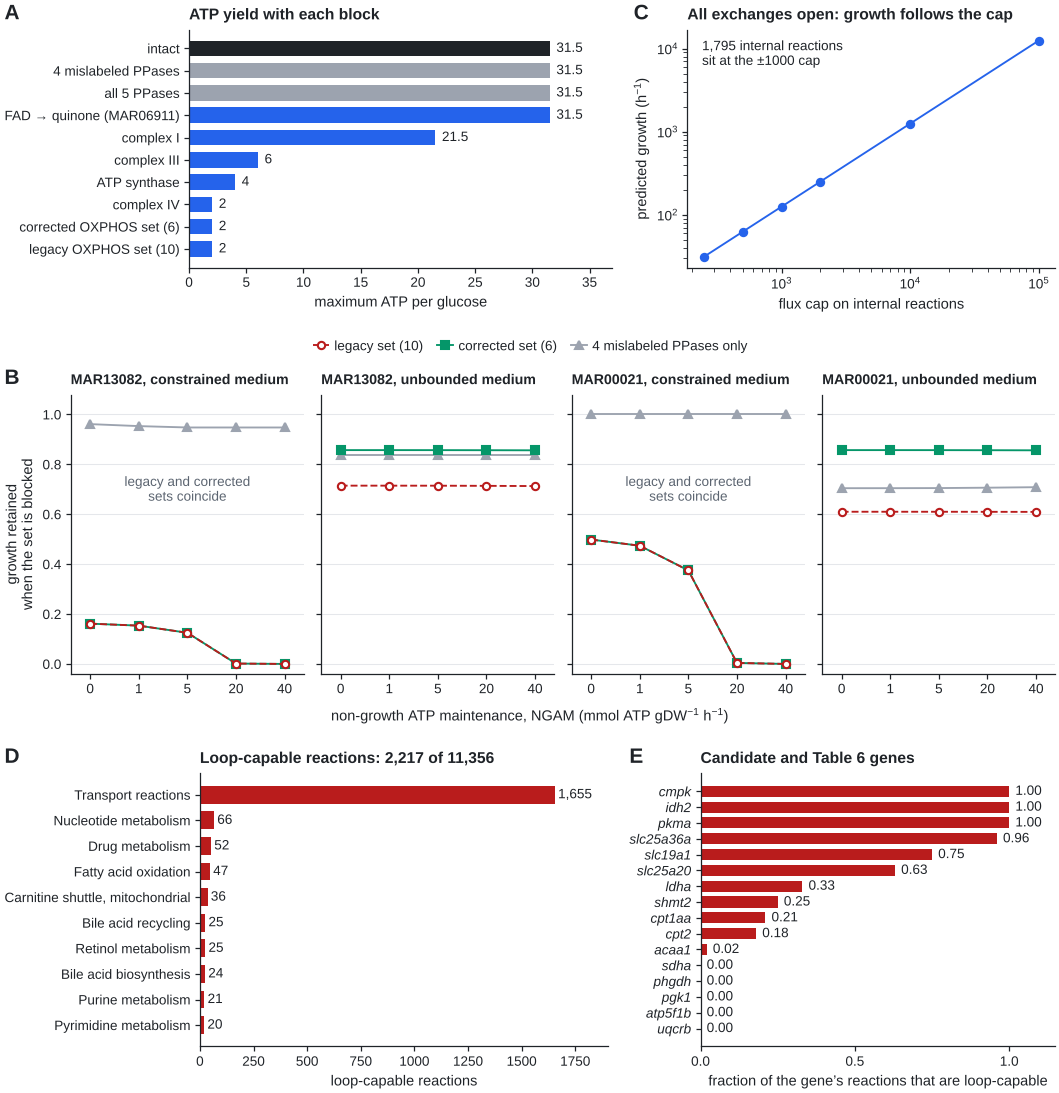

In [16]:
setup()
fig = new_figure(185)
top, mid, bot = fig.subfigures(3, 1, height_ratios=[0.95, 1.2, 1.05])
# ---- A: ATP yield audit
axA, axC = top.subplots(1, 2, width_ratios=[1.15, 1])
lab = ['intact', 'PPase4', 'PPase5', 'FAD->Q (MAR06911)', 'complex I', 'complex III', 'ATP synthase', 'complex IV', 'corrected6', 'legacy10']
NICE = {'corrected6': 'corrected OXPHOS set (6)', 'legacy10': 'legacy OXPHOS set (10)', 'PPase4': '4 mislabeled PPases', 'PPase5': 'all 5 PPases',
        'FAD->Q (MAR06911)': 'FAD → quinone (MAR06911)'}
vals = [ATPY[l] for l in lab]; colsb = [C['no'] if l in ('PPase4', 'PPase5') else C['accent'] for l in lab]; colsb[0] = INK
axA.barh(range(len(lab)), vals, color=colsb, height=0.7); axA.set_yticks(range(len(lab))); axA.set_yticklabels([NICE.get(l, l) for l in lab])
axA.invert_yaxis(); axA.set_xlabel('maximum ATP per glucose'); axA.set_xlim(0, 37); axA.set_title('ATP yield with each block')
for i, v in enumerate(vals): axA.text(v + 0.6, i, f'{v:g}', va='center', fontsize=6.5)
panel(axA, 'A')
# ---- C: unbounded medium, growth vs cap
axC.loglog(CAPS.cap, CAPS.growth, 'o-', color=C['accent'], ms=3.5, lw=0.9)
axC.set_xlabel('flux cap on internal reactions'); axC.set_ylabel('predicted growth (h$^{-1}$)')
axC.set_title('All exchanges open: growth follows the cap')
axC.text(0.04, 0.96, f'{at_cap:,} internal reactions\nsit at the ±1000 cap', transform=axC.transAxes, va='top', fontsize=6.5)
panel(axC, 'C')
# ---- B: OXPHOS / PPase factorial as four small panels
axs = mid.subplots(1, 4, sharey=True)
sub = FAC[(FAC.capacity == 0)]; NG = [0, 1, 5, 20, 40]; xpos = np.arange(len(NG))
STY = {'legacy10': dict(color=C['bad'], marker='o', ls='--', mfc='white', label='legacy set (10)', zorder=3),
       'corrected6': dict(color=C['ok'], marker='s', ls='-', label='corrected set (6)', zorder=2),
       'PPase4': dict(color=C['no'], marker='^', ls='-', label='4 mislabeled PPases only', zorder=1)}
for ax, (o, md) in zip(axs, [(o, md) for o in ['MAR13082', 'MAR00021'] for md in ['constrained', 'unbounded']]):
    for sn, kw in STY.items():
        v = [sub[(sub.objective == o) & (sub.medium == md) & (sub.NGAM == n) & (sub.set == sn)].growth_rel.values[0] for n in NG]
        ax.plot(xpos, v, ms=3.5, lw=0.9, **kw)
    ax.set_xticks(xpos); ax.set_xticklabels(NG); ax.set_ylim(-0.04, 1.08); ax.set_xlim(-0.4, len(NG) - 0.6)
    ax.set_title(f'{o}, {md} medium', fontsize=6.8)
    ax.grid(axis='y', color=GRID, lw=0.5); ax.set_axisbelow(True)
    if md == 'constrained': ax.text(0.5, 0.62, 'legacy and corrected\nsets coincide', transform=ax.transAxes, ha='center', fontsize=6.5, color=MUTED)
axs[0].set_ylabel('growth retained\nwhen the set is blocked')
mid.supxlabel('non-growth ATP maintenance, NGAM (mmol ATP gDW$^{-1}$ h$^{-1}$)', fontsize=FS['base'])
mid.legend(handles=axs[0].get_lines(), loc='outside upper center', ncol=3)
panel(axs[0], 'B')
# ---- D: TIC audit by subsystem; E: candidate genes
axD, axE = bot.subplots(1, 2, width_ratios=[1.15, 1])
topS = TIC.subsystem.value_counts().head(10)[::-1]
axD.barh(range(len(topS)), topS.values, color=C['bad'], height=0.7); axD.set_yticks(range(len(topS)))
axD.set_yticklabels([t.replace(' (mitochondrial)', ', mitochondrial') for t in topS.index])
for i, v in enumerate(topS.values): axD.text(v + 15, i, f'{v:,}', va='center', fontsize=6.5)
axD.set_xlim(0, topS.max() * 1.15); axD.set_xlabel('loop-capable reactions')
axD.set_title(f'Loop-capable reactions: {len(TIC):,} of 11,356'); panel(axD, 'D')
tg = TG.sort_values('fraction')
axE.barh(range(len(tg)), tg.fraction, color=[C['bad'] if f > 0 else C['no'] for f in tg.fraction], height=0.7)
for i, f in enumerate(tg.fraction): axE.text(f + 0.02, i, f'{f:.2f}', va='center', fontsize=6.5)
axE.set_yticks(range(len(tg))); axE.set_yticklabels(tg.index, style='italic'); axE.set_xlim(0, 1.15); axE.set_xticks([0, 0.5, 1])
axE.set_xlabel('fraction of the gene’s reactions that are loop-capable'); axE.set_title('Candidate and Table 6 genes'); panel(axE, 'E')
save(fig, 'Fig4_model_audit'); plt.show()

## 8. Expression-constrained flux (E-Flux) with binding capacities, and metacell-level flux tests
**Conventional setting:** bounds = s_hat x (+-1000), s_hat = max(s / max s, eps). Uptake is of order 1 to 20, so expression
bounds of 20 to 1000 rarely bind. **Here:** bounds = s_hat x U with s normalized to its 95th percentile (capped at 1),
eps = 0.05, and a global capacity U swept from 1000 down to 20. U = 50 is the primary setting (median state keeps
about half of reference growth, so expression shapes the solution); U = 100 is the sensitivity setting.
Each solution is pFBA, then checked for loops with CycleFreeFlux (L1 distance to the nearest loop-free flux).

**Replication unit.** Each state is split into ~20-cell metacells
(k-means on PCA within state), and every metacell gets its own model: 384 models, so states can be compared
with between-unit variance.

In [17]:
# Pseudobulk (mean CP10k of model genes) per group, and ~20-cell metacells within each group
from sklearn.cluster import KMeans
grp = a.obs.lineage.astype(str).copy(); grp.loc[e.obs_names] = e.obs.state.astype(str).values
grp = grp[~grp.isin(['Endothelial', 'HE/EMP', 'unresolved'])]
if not cached('results/metacells_meta.csv'):
    aa = a[grp.index].copy(); aa.obs['group'] = grp.values
    mgenes = [g.id for g in m0.genes if g.id in aa.raw.var_names]
    cp = aa.raw[:, mgenes].X.copy(); cp.data = np.expm1(cp.data)
    groups = sorted(aa.obs.group.unique())
    pd.DataFrame({g: np.asarray(cp[(aa.obs.group == g).values].mean(0)).ravel() for g in groups}, index=mgenes).to_csv('results/mean_cp10k_by_group.csv')
    pd.DataFrame({g: np.asarray((cp[(aa.obs.group == g).values] > 0).mean(0)).ravel() for g in groups}, index=mgenes).to_csv('results/detect_frac_by_group.csv')
    aa.obs[['sample', 'lineage', 'group', 'phase', 'S_score', 'G2M_score', 'n_genes_by_counts', 'total_counts']].to_csv('results/cell_groups.csv')
    rows, prof = [], []
    for g, idx in aa.obs.groupby('group').indices.items():
        k = max(3, len(idx) // 20); lab = KMeans(k, n_init=4, random_state=0).fit_predict(aa.obsm['X_pca'][idx, :30])
        for j in range(k):
            sel = idx[lab == j]
            if len(sel) < 5: continue
            prof.append(np.asarray(cp[sel].mean(0)).ravel())
            rows.append(dict(mc=f'{g}|{j}', group=g, n=len(sel), fracG2M=(aa.obs.phase.values[sel] == 'G2M').mean(), fracS=(aa.obs.phase.values[sel] == 'S').mean()))
    meta_ = pd.DataFrame(rows).set_index('mc'); meta_.to_csv('results/metacells_meta.csv')
    pd.DataFrame(np.vstack(prof).T, index=mgenes, columns=meta_.index).to_csv('results/metacells_cp10k.csv.gz')
print(pd.read_csv('results/metacells_meta.csv', index_col=0).groupby('group').size().to_dict())

{'Epithelium': 15, 'Erythroid': 101, 'Fibroblast': 12, 'HE_EMP': 5, 'ISV_cyc': 9, 'ISV_tip': 18, 'LPM/cardiac': 2, 'Macrophage': 19, 'Mesenchyme': 16, 'Muscle': 8, 'Myeloid': 5, 'Neural prog.': 21, 'Neuron': 3, 'Periderm': 6, 'Post. mes.': 10, 'Xantho.': 2, 'aCran': 9, 'aDA': 21, 'aTrunk_mixed': 5, 'angioblast': 20, 'angioblast_cyc': 8, 'cranV': 17, 'cranV_cyc': 8, 'endocard': 2, 'vCV': 20, 'vPCV': 12, 'vPCV_cyc': 10}


In [18]:
from pipeline import *
ref, net = load_ref(); MU_REF0 = net.fba()
M, L = expression()
if cached('results/eflux_sweep_groups.csv'):
    SW = pd.read_csv('results/eflux_sweep_groups.csv')
else:
    rows = []
    for U, eps, norm, label in [(1000, 0.05, 'max', 'conventional (U=1000, s/max)'), (1000, 0.05, 'p95', 'U=1000'), (200, 0.05, 'p95', 'U=200'),
                                (100, 0.05, 'p95', 'U=100'), (50, 0.05, 'p95', 'U=50'), (20, 0.05, 'p95', 'U=20')]:
        for g in M.columns:
            eflux_global(net, ref, M[g], U, eps, norm); r = solve_unit(net, loopcheck=False)
            if r is None: continue
            ro, gap, atb, v = r; rows.append(dict(setting=label, U=U, group=g, at_bound=atb, growth_rel=ro['growth'] / MU_REF0, **ro))
    SW = pd.DataFrame(rows); SW.to_csv('results/eflux_sweep_groups.csv', index=False)
SW.groupby('setting')[['growth_rel', 'at_bound', 'glyc_ATP_frac', 'PPAT_per_growth']].agg(['median', 'min', 'max']).round(3)

growth_rel               at_bound          \
                                 median    min    max   median min max   
setting                                                                  
U=100                             0.778  0.498  0.931     28.0  14  39   
U=1000                            1.000  1.000  1.000      1.0   1   2   
U=20                              0.189  0.115  0.309     38.0  24  92   
U=200                             0.942  0.773  0.942     14.0   7  24   
U=50                              0.469  0.295  0.756     33.0  23  80   
conventional (U=1000, s/max)      0.872  0.792  1.000      8.0   3  10   

                             glyc_ATP_frac               PPAT_per_growth  \
                                    median    min    max          median   
setting                                                                    
U=100                                0.240  0.118  0.412           0.102   
U=1000                               0.185  0.142  0.241           0.102   
U=20                                 0.268  0.058  0.530           0.102   
U=200                                0.204  0.159  0.326           0.102   
U=50                                 0.308  0.093  0.464           0.102   
conventional (U=1000, s/max)         0.261  0.175  0.400           0.102   

                                            
                                min    max  
setting                                     
U=100                         0.102  0.102  
U=1000                        0.102  0.102  
U=20                          0.102  0.102  
U=200                         0.102  0.102  
U=50                          0.102  0.102  
conventional (U=1000, s/max)  0.102  0.102

In [19]:
if cached('results/eflux_metacells.csv'):
    MC = pd.read_csv('results/eflux_metacells.csv')
else:
    P = pd.read_csv('results/metacells_cp10k.csv.gz', index_col=0); meta = pd.read_csv('results/metacells_meta.csv', index_col=0)
    keep = meta.index[meta.group.isin(EC_STATES + ['Erythroid', 'Muscle', 'Neural prog.', 'Macrophage', 'Fibroblast'])]
    rows = []
    for U in [50, 100]:
        for mc in keep:
            eflux_global(net, ref, P[mc], U, 0.05, 'p95'); r = solve_unit(net, loopcheck=True)
            if r is None: continue
            ro, gap, atb, v = r
            rows.append(dict(U=U, mc=mc, group=meta.loc[mc, 'group'], fracG2M=meta.loc[mc, 'fracG2M'], fracS=meta.loc[mc, 'fracS'],
                             loop_gap=gap, at_bound=atb, growth_rel=ro['growth'] / MU_REF0, **ro))
    MC = pd.DataFrame(rows); MC.to_csv('results/eflux_metacells.csv', index=False)
print('metacell models:', MC.groupby('U').size().to_dict(), '| pFBA loop gap (L1) max:', MC.loop_gap.max())

metacell models: {50: 325, 100: 325} | pFBA loop gap (L1) max: 2.438296125507937e-08


In [20]:
from scipy.stats import mannwhitneyu
def cliffs(x, y):
    x, y = np.asarray(x), np.asarray(y); return (np.sign(x[:, None] - y[None, :])).mean()
CMPS = [('ISV_tip vs other EC', ['ISV_tip'], [s for s in EC_STATES if s not in ('ISV_tip', 'HE_EMP', 'endocard')]),
        ('ISV_tip vs ISV_cyc', ['ISV_tip'], ['ISV_cyc']),
        ('ISV (tip+cyc) vs quiescent', ['ISV_tip', 'ISV_cyc'], QUIESCENT),
        ('cycling vs quiescent', CYCLING, QUIESCENT),
        ('arterial vs venous', ['aDA', 'aCran'], ['vPCV', 'vCV', 'cranV'])]
READ = ['glyc_ATP_frac', 'lac_per_glc', 'o2_uptake', 'glc_uptake', 'growth_rel', 'PHGDH', 'CACT', 'PPAT_per_growth']
rows = []
for U in [50, 100]:
    d = MC[MC.U == U]
    for name, A_, B_ in CMPS:
        for rd in READ:
            x = d[d.group.isin(A_)][rd].dropna(); y = d[d.group.isin(B_)][rd].dropna()
            p = mannwhitneyu(x, y).pvalue if len(x) > 2 and len(y) > 2 and (x.std() > 0 or y.std() > 0) else 1.0
            rows.append(dict(U=U, comparison=name, readout=rd, n_a=len(x), n_b=len(y), median_a=x.median(), median_b=y.median(), cliffs_delta=cliffs(x, y), p=p))
FT = pd.DataFrame(rows); FT['q'] = multipletests(FT.p, method='fdr_bh')[1]
FT.to_csv('results/TableS_flux_level_metacell_tests.csv', index=False)
FT[FT.readout.isin(['glyc_ATP_frac', 'lac_per_glc', 'PPAT_per_growth'])].round(3)

,U,comparison,readout,n_a,n_b,median_a,median_b,cliffs_delta,p,q
0,50,ISV_tip vs other EC,glyc_ATP_frac,18,139,0.346,0.273,0.282,0.052,0.199
1,50,ISV_tip vs other EC,lac_per_glc,18,139,0.910,0.675,0.068,0.640,0.959
7,50,ISV_tip vs other EC,PPAT_per_growth,18,139,0.102,0.102,-0.005,0.974,1.000
8,50,ISV_tip vs ISV_cyc,glyc_ATP_frac,18,9,0.346,0.386,-0.086,0.738,0.959
9,50,ISV_tip vs ISV_cyc,lac_per_glc,18,9,0.910,1.145,-0.321,0.189,0.477
15,50,ISV_tip vs ISV_cyc,PPAT_per_growth,18,9,0.102,0.102,-0.068,0.797,0.959
16,50,ISV (tip+cyc) vs quiescent,glyc_ATP_frac,27,79,0.360,0.279,0.293,0.024,0.111
17,50,ISV (tip+cyc) vs quiescent,lac_per_glc,27,79,0.997,0.751,0.039,0.766,0.959
23,50,ISV (tip+cyc) vs quiescent,PPAT_per_growth,27,79,0.102,0.102,0.050,0.701,0.959
24,50,cycling vs quiescent,glyc_ATP_frac,35,79,0.257,0.279,-0.070,0.555,0.926


### Figure 5. Expression constraints, structural coupling of biosynthetic flux, and metacell-level flux tests

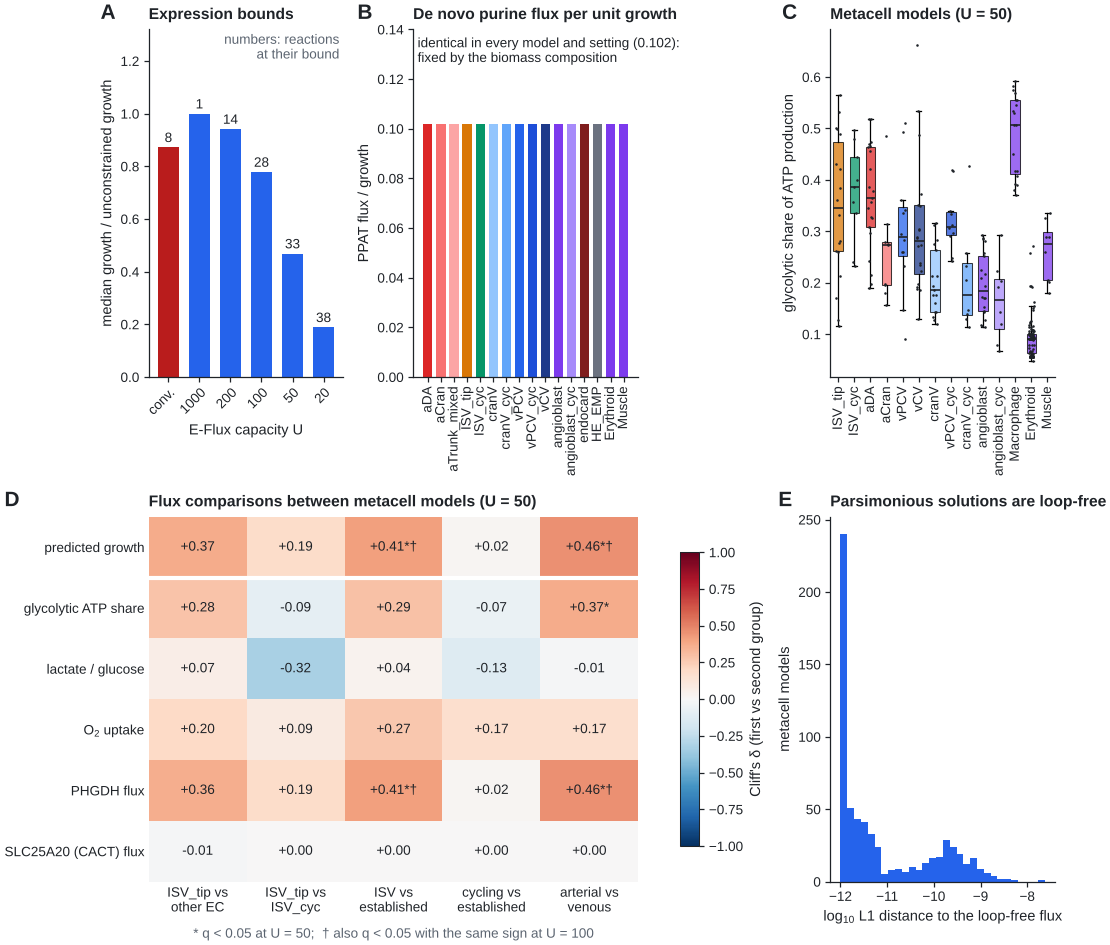

In [21]:
setup()
fig = new_figure(160)
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.05], width_ratios=[0.95, 1.1, 1.1])
order_set = ['conventional (U=1000, s/max)', 'U=1000', 'U=200', 'U=100', 'U=50', 'U=20']
ax = fig.add_subplot(gs[0, 0]); med = SW.groupby('setting').growth_rel.median().loc[order_set]; atb = SW.groupby('setting').at_bound.median().loc[order_set]
ax.bar(range(6), med, color=[C['bad']] + [C['accent']] * 5, width=0.7)
for i, (g_, b_) in enumerate(zip(med, atb)): ax.text(i, g_ + 0.02, f'{int(b_)}', ha='center', fontsize=6.5)
ax.set_xticks(range(6)); ax.set_xticklabels(['conv.', '1000', '200', '100', '50', '20'], rotation=45, ha='right', rotation_mode='anchor')
ax.set_xlabel('E-Flux capacity U'); ax.set_ylabel('median growth / unconstrained growth'); ax.set_title('Expression bounds')
ax.text(0.98, 0.99, 'numbers: reactions\nat their bound', transform=ax.transAxes, ha='right', va='top', fontsize=6.5, color=MUTED)
ax.set_ylim(0, 1.32); panel(ax, 'A')
ax = fig.add_subplot(gs[0, 1]); dd = SW[SW.setting == 'U=50'].set_index('group')
grp = [g for g in EC_STATES if g in dd.index] + ['Erythroid', 'Muscle']
ax.bar(range(len(grp)), dd.loc[grp, 'PPAT_per_growth'], color=[STATE_COL.get(g, C['nonec']) for g in grp], width=0.7)
ax.set_xticks(range(len(grp))); ax.set_xticklabels(grp, rotation=90); ax.set_ylabel('PPAT flux / growth'); ax.set_ylim(0, 0.14)
ax.set_title('De novo purine flux per unit growth')
ax.text(0.02, 0.98, 'identical in every model and setting (0.102):\nfixed by the biomass composition', transform=ax.transAxes, va='top', fontsize=6.5)
panel(ax, 'B')
ax = fig.add_subplot(gs[0, 2]); d50 = MC[MC.U == 50]
grp2 = [g for g in ['ISV_tip', 'ISV_cyc', 'aDA', 'aCran', 'vPCV', 'vCV', 'cranV', 'vPCV_cyc', 'cranV_cyc', 'angioblast', 'angioblast_cyc', 'Macrophage', 'Erythroid', 'Muscle'] if g in set(d50.group)]
data = [d50[d50.group == g].glyc_ATP_frac.dropna() for g in grp2]
bp = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color=INK, lw=0.8), whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6))
for p_, g in zip(bp['boxes'], grp2): p_.set_facecolor(STATE_COL.get(g, C['nonec'])); p_.set_alpha(0.75); p_.set_linewidth(0.5)
for i, dv in enumerate(data): ax.scatter(np.full(len(dv), i + 1) + np.random.default_rng(i).uniform(-0.15, 0.15, len(dv)), dv, s=1.5, color=INK, zorder=3, linewidths=0)
ax.set_xticks(range(1, len(grp2) + 1)); ax.set_xticklabels(grp2, rotation=90); ax.set_ylabel('glycolytic share of ATP production')
ax.set_title('Metacell models (U = 50)'); panel(ax, 'C')
ax = fig.add_subplot(gs[1, :2])
RD = {'growth_rel': 'predicted growth', 'glyc_ATP_frac': 'glycolytic ATP share', 'lac_per_glc': 'lactate / glucose', 'o2_uptake': 'O$_2$ uptake',
      'PHGDH': 'PHGDH flux', 'CACT': 'SLC25A20 (CACT) flux'}
CN = [c_[0] for c_ in CMPS]
CNL = {'ISV_tip vs other EC': 'ISV_tip vs\nother EC', 'ISV_tip vs ISV_cyc': 'ISV_tip vs\nISV_cyc', 'ISV (tip+cyc) vs quiescent': 'ISV vs\nestablished',
       'cycling vs quiescent': 'cycling vs\nestablished', 'arterial vs venous': 'arterial vs\nvenous'}
piv = lambda U_, v_: FT[(FT.U == U_) & FT.readout.isin(RD)].pivot(index='readout', columns='comparison', values=v_).loc[list(RD), CN]
Hm, Hq, Hm2, Hq2 = piv(50, 'cliffs_delta'), piv(50, 'q'), piv(100, 'cliffs_delta'), piv(100, 'q')
im = ax.imshow(Hm.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
for i in range(Hm.shape[0]):
    for j in range(Hm.shape[1]):
        star = '*' if Hq.iloc[i, j] < 0.05 else ''
        rob = '†' if (Hq.iloc[i, j] < 0.05 and Hq2.iloc[i, j] < 0.05 and np.sign(Hm.iloc[i, j]) == np.sign(Hm2.iloc[i, j])) else ''
        ax.text(j, i, f'{Hm.iloc[i, j]:+.2f}{star}{rob}', ha='center', va='center', fontsize=6.5, color='white' if abs(Hm.iloc[i, j]) > 0.6 else INK)
ax.axhline(0.5, color='white', lw=2)
ax.set_yticks(range(len(RD))); ax.set_yticklabels(RD.values()); ax.set_xticks(range(len(CN))); ax.set_xticklabels([CNL.get(c_, c_) for c_ in CN])
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, aspect=15); cb.set_label("Cliff's δ (first vs second group)"); cb.outline.set_linewidth(0.5)
ax.set_title('Flux comparisons between metacell models (U = 50)')
ax.set_xlabel('* q < 0.05 at U = 50;  † also q < 0.05 with the same sign at U = 100', fontsize=6.5, color=MUTED, labelpad=6)
panel(ax, 'D')
ax = fig.add_subplot(gs[1, 2])
ax.hist(np.log10(MC.loop_gap.clip(lower=1e-12)), bins=30, color=C['accent'])
ax.set_xlabel('log$_{10}$ L1 distance to the loop-free flux'); ax.set_ylabel('metacell models'); ax.set_title('Parsimonious solutions are loop-free'); panel(ax, 'E')
save(fig, 'Fig5_eflux_metacells'); plt.show()

## 9. Context-specific model ensemble and knockout screen with full lineage controls
Four ensemble members: FASTCORE on local-T2 cores at three threshold settings (loose 15/65, default 25/75,
strict 40/85 percentiles) and GIMME (threshold = local-T2 upper bound). Every one of the 27 groups (14 endothelial/HE
states, 13 non-endothelial lineages) gets a model in every member. FASTCORE extraction runs with maintenance off and
exchanges outside the core; a closure step then restores micronutrient routes that the eps-support threshold drops
(biomass at 10% of the reference optimum with NGAM = 1). Every gene whose knockout disables at least one reaction is screened.

**Calling rules.** *Two-lineage rule:* inhibition of at least 0.10 in sprouting endothelium (ISV_tip + ISV_cyc) and
none in erythroid and muscle. *All-lineage rule:* the same, plus no inhibition in any of the 13 non-endothelial lineages and
within-endothelium selectivity (sprouting minus quiescent) of at least 0.10.

In [22]:
MEMBERS = [('fastcore', 'loose'), ('fastcore', 'default'), ('fastcore', 'strict'), ('gimme', 'default')]
for algo, setting in MEMBERS:
    fn = f'results/ko_{algo}_{setting}_baseline.csv'
    if cached(fn): continue
    cfn = f'results/ctx_{algo}_{setting}.json'
    ctx = json.load(open(cfn)) if cached(cfn) else build_context(ref, net, setting, algo, L=L)
    json.dump(ctx, open(cfn, 'w'))
    ko_screen(net, ctx).to_csv(fn)

def summarize(fn):
    R = pd.read_csv(fn, index_col=0); wt = R.loc['__WT__']; R = R.drop('__WT__').fillna(1); inh = 1 - R
    d = pd.DataFrame({'sprout': inh[SPROUT].mean(1), 'tip': inh['ISV_tip'], 'isv_cyc': inh['ISV_cyc'], 'cycling': inh[CYCLING].mean(1),
                      'quiescent': inh[QUIESCENT].mean(1), 'eryth': inh['Erythroid'], 'muscle': inh['Muscle'],
                      'nonEC_max': inh[NONEC].max(1), 'nonEC_n_hit': (inh[NONEC] > 0.01).sum(1)})
    d['sel_within'] = d.sprout - d.quiescent; d['margin_all'] = d.sprout - d.nonEC_max
    d['call_two'] = (d.sprout >= 0.10) & (d.eryth <= 0.01) & (d.muscle <= 0.01)
    d['call_all'] = (d.sprout >= 0.10) & (d.nonEC_max <= 0.01) & (d.sel_within >= 0.10)
    return d, inh, wt
ENS = {f'{a_}/{s_}': summarize(f'results/ko_{a_}_{s_}_baseline.csv') for a_, s_ in MEMBERS}
sizes = pd.DataFrame({k: pd.Series({g: len(v) for g, v in json.load(open(f"results/ctx_{k.replace('/', '_')}.json")).items()}) for k in ENS})
print('model sizes (reactions), median per member:', sizes.median().to_dict())
calls = pd.DataFrame({k: pd.Series({'two-lineage rule': list(d.index[d.call_two]), 'all-lineage rule': list(d.index[d.call_all])}) for k, (d, _, _) in ENS.items()}).T
calls

model sizes (reactions), median per member: {'fastcore/loose': 7131.0, 'fastcore/default': 6911.0, 'fastcore/strict': 6587.0, 'gimme/default': 3333.0}


,two-lineage rule,all-lineage rule
fastcore/loose,"[acox1, ada, dldh, dlst, fh, lcat, nmnat1, sdh...",[]
fastcore/default,"[ada, dldh, dlst, fh, lcat, sdha, sdhb, sdhc, ...",[]
fastcore/strict,"[acat2, cpt2, lcat, nmnat1, slc25a19]","[lcat, slc25a19]"
gimme/default,"[fdps, idh2, mdh2, ptdss1a, slc25a36a]",[slc25a36a]


In [23]:
CONV = ['slc25a20', 'slc25a36a', 'idh2', 'uqcrb', 'sdha', 'suclg1', 'slc19a1', 'acaa1', 'cmpk']
union = sorted(set(CONV) | {g for d, _, _ in ENS.values() for g in d.index[d.call_two | d.call_all]})
ROB = pd.DataFrame({k: d.reindex(union).sprout for k, (d, _, _) in ENS.items()})
ROB_call_m = pd.DataFrame({k: d.reindex(union).call_two.fillna(False) for k, (d, _, _) in ENS.items()})
ROB_call_s = pd.DataFrame({k: d.reindex(union).call_all.fillna(False) for k, (d, _, _) in ENS.items()})
ROBT = pd.DataFrame({'members calling (two-lineage rule)': ROB_call_m.sum(1), 'members calling (all-lineage rule)': ROB_call_s.sum(1),
                     'sprouting inhibition, median over members': ROB.median(1),
                     'max non-EC inhibition, median over members': pd.DataFrame({k: d.reindex(union).nonEC_max for k, (d, _, _) in ENS.items()}).median(1)})
ROBT.to_csv('results/TableS_candidate_robustness.csv'); ROBT.sort_values(['members calling (all-lineage rule)', 'members calling (two-lineage rule)'], ascending=False).round(2)

,members calling (two-lineage rule),members calling (all-lineage rule),"sprouting inhibition, median over members","max non-EC inhibition, median over members"
lcat,3,1,0.75,1.00
slc25a19,1,1,0.00,0.50
slc25a36a,1,1,0.00,0.00
ada,2,0,1.00,1.00
dldh,2,0,0.12,0.27
dlst,2,0,0.12,0.27
fh,2,0,0.12,0.27
nmnat1,2,0,0.50,1.00
sdha,2,0,0.12,0.27
sdhb,2,0,0.12,0.27


## 10. Mechanism: why is each all-lineage call lethal in some models and not in others?
For a gene called in a member, compare the lethal model with a non-lethal endothelial model of the same member and
find the smallest set of reactions from the non-lethal model that restores growth after the knockout.

In [24]:
def rescue(member, gene, lethal_group, ok_group):
    ctx = json.load(open(f"results/ctx_{member.replace('/', '_')}.json"))
    ko = net.gene_ko[gene]; base = set(ctx[lethal_group]); extra = set(ctx[ok_group]) - base
    mask_net(net, sorted(base | extra))
    for i in ko: net.lb[i] = net.ub[i] = 0.0
    net._h = None
    sup = gapfill_support(net, [net.idx[r] for r in base if r in net.idx], net.obj, 0.5)
    add = [net.ids[i] for i in sup if net.ids[i] in extra]
    out = []
    for r_ in add:
        rx = ref.reactions.get_by_id(r_); out.append(dict(reaction=r_, subsystem=rx.subsystem, equation=rx.build_reaction_string(True), GPR=rx.gene_reaction_rule))
    net.reset_bounds(); return pd.DataFrame(out)
MECH = []
for k, (d, inh, wt) in ENS.items():
    for g in d.index[d.call_all]:
        lethal = inh.loc[g, SPROUT].idxmax()                                   # the sprouting model that loses growth
        others = [x for x in SPROUT if x != lethal and inh.loc[g, x] < 0.01]   # nearest relative first: the other ISV model
        ok = others[0] if others else inh.loc[g, QUIESCENT].idxmin()
        r_ = rescue(k, g, lethal, ok); r_.insert(0, 'gene', g); r_.insert(1, 'member', k); r_.insert(2, 'lethal_in', lethal); r_.insert(3, 'rescued_by_model', ok)
        MECH.append(r_)
MECH = pd.concat(MECH) if MECH else pd.DataFrame(); MECH.to_csv('results/TableS_mechanism_rescue.csv', index=False); MECH

,gene,member,lethal_in,rescued_by_model,reaction,subsystem,equation,GPR
0,lcat,fastcore/strict,ISV_cyc,ISV_tip,MAR02623,Carnitine shuttle (cytosolic),CoA + pentadecanoylcarnitine <=> L-carnitine +...,cpt1a2b or cpt1aa or cpt1ab or cpt1b
1,lcat,fastcore/strict,ISV_cyc,ISV_tip,MAR02678,Carnitine shuttle (cytosolic),CoA + eicosanoylcarnitine <=> eicosanoyl-CoA +...,cpt1a2b or cpt1aa or cpt1ab or cpt1b
2,lcat,fastcore/strict,ISV_cyc,ISV_tip,MAR02787,Carnitine shuttle (endoplasmic reticular),dodecanoylcarnitine + L-carnitine <=> dodecano...,slc22a21
3,lcat,fastcore/strict,ISV_cyc,ISV_tip,MAR02788,Carnitine shuttle (endoplasmic reticular),CoA + dodecanoylcarnitine <=> lauroyl-CoA + L-...,crata
4,lcat,fastcore/strict,ISV_cyc,ISV_tip,MAR02789,Carnitine shuttle (endoplasmic reticular),L-carnitine + tridecanoylcarnitine <=> L-carni...,slc22a21
...,...,...,...,...,...,...,...,...
78,lcat,fastcore/strict,ISV_cyc,ISV_tip,MAR03683,Formation and hydrolysis of cholesterol esters,"10,13,16-docosatrienoyl-CoA + cholesterol --> ...",soat1 or soat2
79,lcat,fastcore/strict,ISV_cyc,ISV_tip,MAR03507,Fatty acid oxidation,"H+ + NADPH + trans,cis,cis,cis,cis-2,12,15,18,...",elovl1b
80,lcat,fastcore/strict,ISV_cyc,ISV_tip,MAR03535,Fatty acid oxidation,"3(S)-hydroxy-tetracosa-12,15,18,21-all-cis-tet...",elovl1b
0,slc25a19,fastcore/strict,ISV_tip,ISV_cyc,MAR04579,Pyrimidine metabolism,Pi + uridine <=> ribose-1-phosphate + uracil,upp1 or upp2


In [25]:
# Expression of the genes behind each rescue reaction, against the member's activity threshold
from ctxlib import localT2
act_, thr_ = localT2(L, *THRESH['default'])
def gpr_genes(gpr): return [g_ for g_ in gpr.replace('(', ' ').replace(')', ' ').replace(' or ', ' ').replace(' and ', ' ').split() if g_ in L.index]
resc_genes = sorted({g_ for gpr in MECH.get('GPR', []) for g_ in gpr_genes(gpr)})
focus = MECH[(MECH.gene == 'slc25a36a')] if len(MECH) and (MECH.gene == 'slc25a36a').any() else MECH.head(1)
focus_genes = [g_ for gpr in focus.get('GPR', []) for g_ in gpr_genes(gpr)]
print('GIMME / local-T2 upper threshold (log1p CP10k):', round(thr_[1], 3))
L.loc[resc_genes, ['ISV_tip', 'ISV_cyc', 'aDA', 'aCran', 'vPCV', 'vCV', 'vPCV_cyc', 'angioblast', 'Erythroid', 'Muscle']].round(3) if resc_genes else None

GIMME / local-T2 upper threshold (log1p CP10k): 0.194


,ISV_tip,ISV_cyc,aDA,aCran,vPCV,vCV,vPCV_cyc,angioblast,Erythroid,Muscle
cpt1aa,0.078,0.083,0.059,0.031,0.088,0.070,0.085,0.105,0.021,0.037
cpt1ab,0.002,0.000,0.020,0.007,0.015,0.010,0.028,0.011,0.117,0.077
cpt1b,0.001,0.000,0.000,0.000,0.002,0.001,0.000,0.000,0.000,0.002
crata,0.029,0.008,0.036,0.028,0.036,0.057,0.026,0.047,0.018,0.008
elovl1b,0.087,0.053,0.080,0.101,0.630,0.580,0.535,0.095,0.005,0.051
guk1a,0.254,0.183,0.242,0.265,0.333,0.243,0.289,0.222,0.468,0.248
slc22a21,0.002,0.000,0.003,0.005,0.005,0.010,0.004,0.011,0.009,0.013
soat1,0.002,0.000,0.002,0.000,0.010,0.000,0.003,0.000,0.000,0.000
upp1,0.000,0.000,0.000,0.000,0.005,0.002,0.002,0.005,0.003,0.000


## 11. Medium sensitivity of the candidate calls
Knockouts of every gene in the union above, in every group, for the FASTCORE-default and GIMME members, across the
three disease media plus carnitine supplementation and a 10-fold lower amino-acid supply.

In [26]:
if cached('results/ko_media_candidates.csv'):
    MED = pd.read_csv('results/ko_media_candidates.csv')
else:
    rows = []
    for member in ['fastcore/default', 'gimme/default']:
        ctx = json.load(open(f"results/ctx_{member.replace('/', '_')}.json"))
        for mname in MEDIA:
            R = ko_screen(net, ctx, medium=full_medium(mname), genes=[g for g in union if g in net.gene_ko])
            wt = R.loc['__WT__']; inh = 1 - R.drop('__WT__').fillna(1)
            for g in inh.index:
                rows.append(dict(member=member, medium=mname, gene=g, sprout=inh.loc[g, SPROUT].mean(), quiescent=inh.loc[g, QUIESCENT].mean(),
                                 nonEC_max=inh.loc[g, NONEC].max(), wt_sprout=wt[SPROUT].mean(), wt_quiescent=wt[QUIESCENT].mean()))
    MED = pd.DataFrame(rows); MED.to_csv('results/ko_media_candidates.csv', index=False)
MED.pivot_table(index='gene', columns=['member', 'medium'], values='sprout').round(2)

member    fastcore/default                                          \
medium          +carnitine baseline hyperglycemia hypoxia ischemia   
gene                                                                 
acaa1                 1.00     1.00          1.00    1.00     1.00   
acat2                 0.00     0.00          0.00    0.00     0.00   
acox1                 1.00     1.00          1.00    1.00     1.00   
ada                   1.00     1.00          1.00    1.00     1.00   
cmpk                  0.00     0.00          0.00    0.00     0.00   
cpt2                  0.00     0.00          0.00    0.00     0.00   
dldh                  0.14     0.14          0.00    0.02     0.10   
dlst                  0.14     0.14          0.00    0.01     0.05   
fdps                  0.00     0.00          0.00    0.00     0.00   
fh                    0.14     0.14          0.00    0.01     0.07   
idh2                  0.00     0.00          0.00    0.00     0.00   
lcat                  1.00     1.00          1.00    1.00     1.00   
mdh2                  0.09     0.09          0.00    0.00     0.00   
nmnat1                0.50     0.50          0.50    0.50     0.50   
ptdss1a               0.00     0.00          0.00    0.00     0.00   
sdha                  0.14     0.14          0.00    0.02     0.13   
sdhb                  0.14     0.14          0.00    0.02     0.13   
sdhc                  0.14     0.14          0.00    0.02     0.13   
sdhdb                 0.14     0.14          0.00    0.02     0.13   
slc19a1               0.00     0.00          0.00    0.00     0.00   
slc19a3a              1.00     1.00          1.00    1.00     1.00   
slc25a19              0.00     0.00          0.00    0.00     0.00   
slc25a20              0.00     0.00          0.00    0.00     0.00   
slc25a36a             0.00     0.00          0.00    0.00     0.00   
slc29a1b              0.00     0.00          0.00    0.00     0.00   
suclg1                0.14     0.14          0.00    0.02     0.13   
uqcrb                 0.74     0.74          0.26    0.08     0.46   

member                    gimme/default                                 \
medium    low amino acids    +carnitine baseline hyperglycemia hypoxia   
gene                                                                     
acaa1                 1.0          1.00     1.00          1.00    1.00   
acat2                 0.0          0.00     0.00          0.00    0.00   
acox1                 1.0          1.00     1.00          1.00    1.00   
ada                   1.0          0.00     0.00          0.00    0.00   
cmpk                  0.0          1.00     1.00          1.00    1.00   
cpt2                  0.0          1.00     1.00          1.00    1.00   
dldh                  0.0          1.00     1.00          1.00    1.00   
dlst                  0.0          0.90     0.90          0.63    0.59   
fdps                  0.0          0.50     0.50          0.50    0.50   
fh                    0.0          0.74     0.74          0.41    0.01   
idh2                  0.0          0.77     0.77          0.36    0.01   
lcat                  1.0          1.00     1.00          1.00    1.00   
mdh2                  0.0          0.77     0.77          0.36    0.01   
nmnat1                0.5          1.00     1.00          1.00    1.00   
ptdss1a               0.0          0.50     0.50          0.50    0.50   
sdha                  0.0          0.92     0.92          0.88    0.63   
sdhb                  0.0          0.92     0.92          0.88    0.63   
sdhc                  0.0          0.92     0.92          0.88    0.63   
sdhdb                 0.0          0.92     0.92          0.88    0.63   
slc19a1               0.0          0.00     0.00          0.00    0.00   
slc19a3a              1.0          0.00     0.00          0.00    0.00   
slc25a19              0.0          0.00     0.00          0.00    0.00   
slc25a20              0.0          0.05     0.05 

### Figure 6. Candidate calls across the model ensemble, rules and media

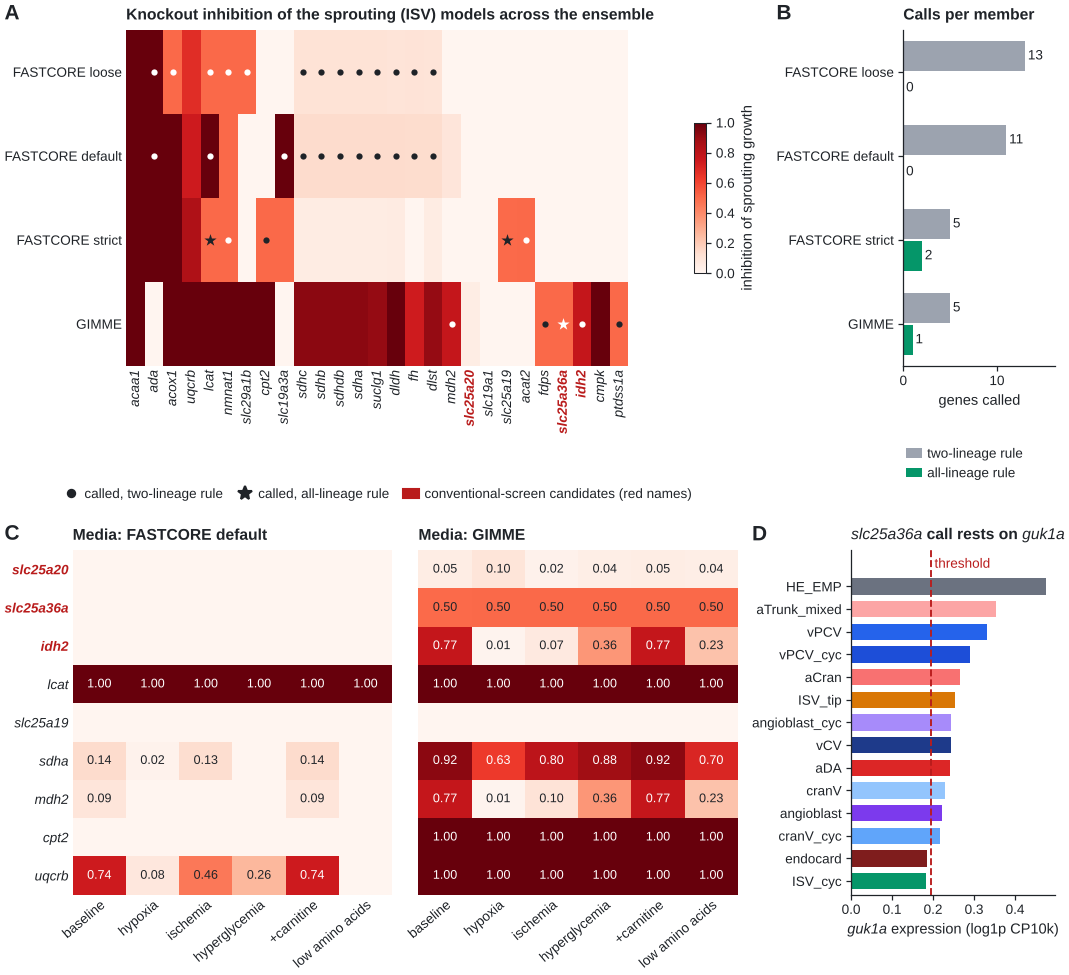

In [27]:
setup()
MEMN = {'fastcore/loose': 'FASTCORE loose', 'fastcore/default': 'FASTCORE default', 'fastcore/strict': 'FASTCORE strict', 'gimme/default': 'GIMME'}
ORIG = ('slc25a20', 'slc25a36a', 'idh2')
fig = new_figure(165)
top, bot = fig.subfigures(2, 1, height_ratios=[1.1, 1])
axA, axB = top.subplots(1, 2, width_ratios=[3.3, 1])
show = ROBT.sort_values('sprouting inhibition, median over members', ascending=False).index.tolist()
H = ROB.loc[show]; im = axA.imshow(H.T.values, aspect='auto', cmap='Reds', vmin=0, vmax=1)
for i, k in enumerate(H.columns):
    for j, g in enumerate(show):
        col = 'white' if H.loc[g, k] > 0.5 else INK
        if ROB_call_s.loc[g, k]: axA.scatter(j, i, marker='*', s=38, color=col, linewidths=0)
        elif ROB_call_m.loc[g, k]: axA.scatter(j, i, marker='o', s=9, color=col, linewidths=0)
axA.set_yticks(range(len(H.columns))); axA.set_yticklabels([MEMN.get(k, k) for k in H.columns]); axA.set_xticks(range(len(show)))
axA.set_xticklabels(show, rotation=90, style='italic'); axA.tick_params(length=0); [s.set_visible(False) for s in axA.spines.values()]
for t in axA.get_xticklabels():
    if t.get_text() in ORIG: t.set_color(C['bad']); t.set_fontweight('bold')
cb = top.colorbar(im, ax=axA, fraction=0.025, pad=0.01, aspect=12); cb.set_label('inhibition of sprouting growth'); cb.outline.set_linewidth(0.5)
axA.set_title('Knockout inhibition of the sprouting (ISV) models across the ensemble')
hd = [mpl.lines.Line2D([], [], marker='o', ls='', ms=3.5, color=INK, label='called, two-lineage rule'),
      mpl.lines.Line2D([], [], marker='*', ls='', ms=7, color=INK, label='called, all-lineage rule'),
      mpl.patches.Patch(color=C['bad'], label='conventional-screen candidates (red names)')]
axA.legend(handles=hd, loc='upper center', bbox_to_anchor=(0.5, -0.34), ncol=3)
panel(axA, 'A')
cnt = pd.DataFrame({'two-lineage': calls['two-lineage rule'].apply(len), 'all-lineage': calls['all-lineage rule'].apply(len)}).loc[H.columns]
yy = np.arange(len(cnt))
axB.barh(yy - 0.19, cnt['two-lineage'], 0.36, color=C['no'], label='two-lineage rule')
axB.barh(yy + 0.19, cnt['all-lineage'], 0.36, color=C['ok'], label='all-lineage rule')
for i, (a1, a2) in enumerate(zip(cnt['two-lineage'], cnt['all-lineage'])):
    axB.text(a1 + 0.3, i - 0.19, str(a1), va='center', fontsize=6.5); axB.text(a2 + 0.3, i + 0.19, str(a2), va='center', fontsize=6.5)
axB.set_yticks(yy); axB.set_yticklabels([MEMN.get(k, k) for k in cnt.index]); axB.set_ylim(len(cnt) - 0.5, -0.5)
axB.set_xlim(0, cnt.values.max() * 1.25); axB.set_xlabel('genes called'); axB.set_title('Calls per member')
axB.legend(loc='upper center', bbox_to_anchor=(0.4, -0.22), ncol=1); panel(axB, 'B')

axC1, axC2, axD = bot.subplots(1, 3, width_ratios=[1.25, 1.25, 0.8])
med_g = [g for g in ['slc25a20', 'slc25a36a', 'idh2', 'lcat', 'slc25a19', 'sdha', 'mdh2', 'cpt2', 'uqcrb'] if g in set(MED.gene)]
mcols = list(MEDIA)
for ax, mb, ttl in [(axC1, 'fastcore/default', 'Media: FASTCORE default'), (axC2, 'gimme/default', 'Media: GIMME')]:
    pv = MED[MED.member == mb].pivot_table(index='gene', columns='medium', values='sprout').reindex(index=med_g, columns=mcols)
    im2 = ax.imshow(pv.values, aspect='auto', cmap='Reds', vmin=0, vmax=1)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.iloc[i, j]
            if np.isfinite(v) and v > 0.005: ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6, color='white' if v > 0.55 else INK)
    ax.set_xticks(range(len(mcols))); ax.set_xticklabels(mcols, rotation=40, ha='right', rotation_mode='anchor')
    ax.set_yticks(range(len(med_g))); ax.set_yticklabels(med_g if ax is axC1 else [], style='italic')
    ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]; ax.set_title(ttl)
for t in axC1.get_yticklabels():
    if t.get_text() in ORIG: t.set_color(C['bad']); t.set_fontweight('bold')
panel(axC1, 'C')
if len(focus_genes):
    gq = focus_genes[0]; vals_ = L.loc[gq, [g for g in EC_STATES if g in L.columns]].sort_values()
    axD.barh(range(len(vals_)), vals_.values, color=[STATE_COL.get(g, C['no']) for g in vals_.index], height=0.72)
    axD.axvline(thr_[1], color=C['bad'], lw=0.9, ls='--'); axD.text(thr_[1], len(vals_) - 0.3, ' threshold', color=C['bad'], fontsize=6.5, va='bottom')
    axD.set_yticks(range(len(vals_))); axD.set_yticklabels(vals_.index); axD.set_ylim(-0.6, len(vals_) + 0.6)
    axD.set_xlabel(f'$\\it{{{gq}}}$ expression (log1p CP10k)'); axD.set_title(f'$\\it{{{focus.gene.iloc[0]}}}$ call rests on $\\it{{{gq}}}$')
    axD.title.set_style('normal'); panel(axD, 'D')
save(fig, 'Fig6_ensemble_screen'); plt.show()

## 12. Literature phenotypes (Table 6) recomputed
Sprouting (ISV_tip + ISV_cyc) and quiescent (aDA, aCran, vPCV, vCV, cranV) pseudobulk E-Flux models (U = 50).
Flux = sum of |flux| over the gene's reactions in the **loop-corrected** pFBA solution. FVA at 90% of optimum on the
gene's highest-flux reaction, plain and loop-corrected (CycleFreeFlux-style; a conservative lower bound on the loop-free
range). Knockout columns from the FASTCORE-default member, plus the number of ensemble members (of 4) in which
the sprouting knockout leaves at most 0.90 of growth.

In [28]:
T6 = {'SLC25A20': 'slc25a20', 'SDH (complex II)': 'sdha', 'CPT1A': 'cpt1aa', 'LDHA': 'ldha', 'ACC': 'acaca', 'FASN': 'fasn', 'PKM2': 'pkma',
      'ATP synthase': 'atp5f1b', 'RRM': 'rrm1', 'SHMT2': 'shmt2', 'HK': 'hk1', 'PHGDH': 'phgdh', 'G6PD': 'g6pd', 'PFKFB3': 'pfkfb3',
      'GLUT1 (slc2a1b)': 'slc2a1b', 'ASNS': 'asns', 'NOS': 'nos2a', 'GLS': 'glsa'}
# reaction reported for each target in Table 6: the gene's highest-flux reaction in the sprouting model,
# fixed here because genes with tied or zero flux have no unique maximum
REP = {'SLC25A20': 'MAR00060', 'SDH (complex II)': 'MAR04652', 'CPT1A': 'MAR02591', 'LDHA': 'MAR04388', 'ACC': 'MAR07673', 'FASN': 'MAR02151',
       'PKM2': 'MAR04421', 'ATP synthase': 'MAR06916', 'RRM': 'MAR04612', 'SHMT2': 'MAR06980', 'HK': 'MAR04487', 'PHGDH': 'MAR03839',
       'G6PD': 'MAR08971', 'PFKFB3': 'MAR04297', 'GLUT1 (slc2a1b)': 'MAR05029', 'ASNS': 'MAR03903', 'NOS': 'MAR20114', 'GLS': 'MAR03892'}
cnt_ = pd.read_csv('results/cell_groups.csv', index_col=0).group.value_counts()
def pooled(groups): w = cnt_.reindex(groups).fillna(0); return (M[groups] * w).sum(1) / w.sum()
sol = {}
for nm, groups in [('sprout', SPROUT), ('quiescent', QUIESCENT)]:
    eflux_global(net, ref, pooled(groups), 50, 0.05, 'p95'); v = net.pfba(); sol[nm] = (net.cycle_free(v), net.lb.copy(), net.ub.copy())
D0 = ENS['fastcore/default'][0]; rows = []
for lab, g in T6.items():
    if g not in ref.genes: rows.append(dict(target=lab, gene=g, note='not in model')); continue
    idx = [net.idx[r.id] for r in ref.genes.get_by_id(g).reactions if r.id in net.idx]
    fs, fq = np.abs(sol['sprout'][0][idx]).sum(), np.abs(sol['quiescent'][0][idx]).sum()
    canon = net.idx[REP[lab]]
    net.lb, net.ub = sol['sprout'][1].copy(), sol['sprout'][2].copy(); net._h = None
    lo, hi = net.fva([canon], frac=0.9); ll, dep = net.loopless_fva([canon], frac=0.9)
    ens_hit = sum(int(d.reindex([g]).sprout.fillna(0).iloc[0] >= 0.10) for d, _, _ in ENS.values())
    rows.append(dict(target=lab, gene=g, reaction=net.ids[canon], flux_ratio_sprout_quiescent=fs / fq if fq > 1e-9 else (np.inf if fs > 1e-9 else np.nan),
                     FVA90=f'{lo[canon]:.2f} to {hi[canon]:.2f}', FVA90_loop_corrected=f'{ll[canon][0]:.2f} to {ll[canon][1]:.2f}', loop_dependent=dep[canon],
                     KO_growth_sprout=1 - D0.reindex([g]).sprout.fillna(0).iloc[0], KO_growth_quiescent=1 - D0.reindex([g]).quiescent.fillna(0).iloc[0],
                     KO_growth_nonEC_min=1 - D0.reindex([g]).nonEC_max.fillna(0).iloc[0], members_KO_le_0_90=ens_hit))
net.reset_bounds()
T6R = pd.DataFrame(rows); T6R.to_csv('results/Table6_recomputed.csv', index=False); T6R.round(2)

,target,gene,reaction,flux_ratio_sprout_quiescent,FVA90,FVA90_loop_corrected,loop_dependent,KO_growth_sprout,KO_growth_quiescent,KO_growth_nonEC_min,members_KO_le_0_90
0,SLC25A20,slc25a20,MAR00060,1.32,-18.76 to 2.50,-2.50 to 2.50,True,1.00,1.00,1.00,0
1,SDH (complex II),sdha,MAR04652,1.39,-14.14 to -6.28,-14.14 to -6.28,False,0.86,0.92,0.73,3
2,CPT1A,cpt1aa,MAR02591,1.26,-3.68 to 3.68,-2.50 to 2.50,True,1.00,1.00,1.00,0
3,LDHA,ldha,MAR04388,0.78,-31.62 to 40.76,-36.12 to 35.62,True,1.00,1.00,1.00,0
4,ACC,acaca,MAR07673,1.33,0.03 to 2.50,0.03 to 2.50,False,0.00,0.00,0.00,4
5,FASN,fasn,MAR02151,1.26,0.01 to 2.48,0.01 to 2.48,False,0.00,0.00,0.00,4
6,PKM2,pkma,MAR04421,1.41,0.00 to 6.63,0.00 to 6.63,False,1.00,1.00,1.00,0
7,ATP synthase,atp5f1b,MAR06916,1.14,23.88 to 31.74,23.88 to 31.74,False,0.49,0.37,0.26,4
8,RRM,rrm1,MAR04612,1.26,0.00 to 2.86,0.00 to 2.86,False,0.00,0.00,0.00,4
9,SHMT2,shmt2,MAR06980,1.26,0.00 to 0.66,0.00 to 0.66,False,0.00,0.00,0.00,4


## 13. Export
Result tables are in `results/` (prefix `TableS_`) and figures in `figures/` (vector PDF and 600 dpi PNG). The SBML models in `models/` are written by `python fluxsprout/export_models.py`.

In [29]:
sorted(os.listdir('results')), sorted(os.listdir('figures'))

(['Table6_recomputed.csv',
  'TableS_ISVcyc_vs_tip_DE.csv',
  'TableS_ISVcyc_vs_tip_pathways.csv',
  'TableS_candidate_robustness.csv',
  'TableS_claims_marker_level.csv',
  'TableS_flux_level_metacell_tests.csv',
  'TableS_mechanism_rescue.csv',
  'TableS_objective_limiting_nutrient.csv',
  'cell_annotations.csv',
  'cell_groups.csv',
  'ctx_fastcore_default.json',
  'ctx_fastcore_loose.json',
  'ctx_fastcore_strict.json',
  'ctx_gimme_default.json',
  'detect_frac_by_group.csv',
  'eflux_metacells.csv',
  'eflux_sweep_groups.csv',
  'fastcc_consistent.json',
  'ko_fastcore_default_baseline.csv',
  'ko_fastcore_loose_baseline.csv',
  'ko_fastcore_strict_baseline.csv',
  'ko_gimme_default_baseline.csv',
  'ko_media_candidates.csv',
  'mean_cp10k_by_group.csv',
  'metacells_cp10k.csv.gz',
  'metacells_meta.csv',
  'oxphos_factorial.csv',
  'qc_all_droplets.csv',
  'tic_reactions.csv'],
 ['Fig1_QC_atlas.pdf',
  'Fig1_QC_atlas.png',
  'Fig2_tip_vs_cycling_ISV.pdf',
  'Fig2_tip_vs_cycling_

## 14. Supplementary figures and tables
Every supplementary figure (S1–S4) and table (S1–S5), and the supplementary data workbook, is generated here from the
objects computed above.

In [30]:
import itertools, os
os.makedirs('supplementary', exist_ok=True)
setup()
# ---- Table S1: quality control per library and cell numbers per lineage and state
ts1a = qsum.copy(); ts1a.index = ['GFP+ mCherry+ (GSM6138416)' if i == 'vascular' else 'GFP+ mCherry- (GSM6138417)' for i in ts1a.index]
ts1b = a.obs.lineage.value_counts().rename('cells').rename_axis('lineage').reset_index()
ts1c = e.obs.state.value_counts().rename('cells').rename_axis('state').reset_index()
ts1a.to_csv('supplementary/TableS1a_qc_per_library.csv'); ts1b.to_csv('supplementary/TableS1b_cells_per_lineage.csv', index=False)
ts1c.to_csv('supplementary/TableS1c_cells_per_state.csv', index=False)
ts1a

,raw,low_genes_or_umi,high_mito,mad_outlier,doublet,kept
GFP+ mCherry- (GSM6138417),6990,1443,1049,0,85,5024
GFP+ mCherry+ (GSM6138416),6390,813,872,0,43,5066


In [31]:
# ---- Table S2: medium, every exchange bound in the baseline and sensitivity media
rows = []
for nm, rid in EXCH.items():
    met = ref.reactions.get_by_id(rid).reactants[0].name if rid in ref.reactions else ''
    r = dict(nutrient=nm, exchange=rid, metabolite=met)
    for mname in MEDIA:
        r[mname] = full_medium(mname).get(nm, 0.0)
    rows.append(r)
TS2 = pd.DataFrame(rows); TS2 = TS2[TS2.exchange.isin([r.id for r in ref.reactions])]   # zinc has no exchange in Zebrafish-GEM
TS2.loc[TS2.nutrient.isin(IONS), list(MEDIA)] = 'unbounded'
TS2.to_csv('supplementary/TableS2_medium.csv', index=False); TS2.head()

,nutrient,exchange,metabolite,baseline,hypoxia,ischemia,hyperglycemia,+carnitine,low amino acids
0,glucose,MAR09034,glucose,10.0,30.0,2.0,40.0,10.0,10.0
1,O2,MAR09048,O2,20.0,1.0,0.8,20.0,20.0,20.0
2,alanine,MAR09061,alanine,1.0,1.0,1.0,1.0,1.0,0.1
3,arginine,MAR09066,arginine,1.0,1.0,1.0,1.0,1.0,0.1
4,asparagine,MAR09062,asparagine,1.0,1.0,1.0,1.0,1.0,0.1


In [32]:
# ---- Table S3: groups, compartments and replicate units
cnt = pd.read_csv('results/cell_groups.csv', index_col=0).group.value_counts()
mcn = MC[MC.U == 50].group.value_counts()
def comp_of(g):
    if g in ('ISV_tip',): return 'tip; sprouting'
    if g == 'ISV_cyc': return 'cycling; sprouting'
    if g in ('vPCV_cyc', 'cranV_cyc', 'angioblast_cyc'): return 'cycling'
    if g in ('aDA', 'aCran'): return 'arterial; established'
    if g in ('vPCV', 'vCV', 'cranV'): return 'venous; established'
    if g in NONEC: return 'non-endothelial control'
    return 'atlas only (not in a compartment)'
groups = [g for g in EC_STATES] + NONEC
TS3 = pd.DataFrame({'group': groups, 'type': ['endothelial / hemogenic state' if g in EC_STATES else 'non-endothelial lineage' for g in groups],
                    'compartment': [comp_of(g) for g in groups], 'cells': [int(cnt.get(g, 0)) for g in groups],
                    'metacells modeled (E-Flux)': [int(mcn.get(g, 0)) for g in groups]})
for k in ENS: TS3[f'reactions, {MEMN.get(k, k)}'] = [int(sizes.loc[g, k]) if g in sizes.index else np.nan for g in groups]
TS3.to_csv('supplementary/TableS3_groups.csv', index=False); TS3

,group,type,compartment,cells,metacells modeled (E-Flux),"reactions, FASTCORE loose","reactions, FASTCORE default","reactions, FASTCORE strict","reactions, GIMME"
0,aDA,endothelial / hemogenic state,arterial; established,430,21,7290,7160,6830,3122
1,aCran,endothelial / hemogenic state,arterial; established,193,9,7365,7328,6943,3659
2,aTrunk_mixed,endothelial / hemogenic state,atlas only (not in a compartment),110,5,6900,6655,6346,3099
3,ISV_tip,endothelial / hemogenic state,tip; sprouting,362,18,7131,6863,6057,3082
4,ISV_cyc,endothelial / hemogenic state,cycling; sprouting,185,9,7273,6915,6611,2923
5,cranV,endothelial / hemogenic state,venous; established,364,17,7220,6925,6717,3158
6,cranV_cyc,endothelial / hemogenic state,cycling,180,8,7023,6796,6019,3141
7,vPCV,endothelial / hemogenic state,venous; established,292,12,7033,6854,6653,3502
8,vPCV_cyc,endothelial / hemogenic state,cycling,202,10,7233,7074,6321,3366
9,vCV,endothelial / hemogenic state,venous; established,443,20,7620,7344,7130,3899


In [33]:
# ---- Table S4: marker panels and cell-cycle genes
TS4 = pd.DataFrame([dict(panel=k, n_genes=len(v), genes=', '.join(v)) for k, v in panels.items()]
                   + [dict(panel='S phase (Tirosh et al., zebrafish orthologs)', n_genes=len(a.uns['cc_genes']['S']), genes=', '.join(a.uns['cc_genes']['S'])),
                      dict(panel='G2/M phase (Tirosh et al., zebrafish orthologs)', n_genes=len(a.uns['cc_genes']['G2M']), genes=', '.join(a.uns['cc_genes']['G2M']))])
TS4.to_csv('supplementary/TableS4_panels.csv', index=False); TS4[['panel', 'n_genes']]

,panel,n_genes
0,glycolysis,42
1,TCA,33
2,OXPHOS,85
3,FAO,19
4,nucleotide,82
5,serine_1C,30
6,carnitine,4
7,PPP,14
8,"S phase (Tirosh et al., zebrafish orthologs)",45
9,"G2/M phase (Tirosh et al., zebrafish orthologs)",50


In [34]:
# ---- Table S5: model quality metrics (computed with COBRApy) for the reference and the extracted models
def quality(m, label):
    internal = [r for r in m.reactions if not r.boundary and not r.id.startswith('MAR1308') and r.id not in ('MAR13082', 'MAR04413', 'MAR00021')]
    mb = cb = 0; nform = 0
    for r in internal:
        try:
            bal = r.check_mass_balance()
        except Exception:
            bal = {'x': 1}
        if all(k == 'charge' for k in bal): mb += 1
        if 'charge' not in bal: cb += 1
    mets = list(m.metabolites)
    return {'model': label, 'reactions': len(m.reactions), 'metabolites': len(mets), 'genes': len(m.genes),
            'internal reactions': len(internal), 'mass balanced (%)': round(100 * mb / len(internal), 1),
            'charge balanced (%)': round(100 * cb / len(internal), 1),
            'metabolites with formula (%)': round(100 * np.mean([bool(x.formula) for x in mets]), 1),
            'metabolites with charge (%)': round(100 * np.mean([x.charge is not None for x in mets]), 1),
            'reactions with GPR (%)': round(100 * np.mean([bool(r.gene_reaction_rule) for r in internal]), 1),
            'reactions with annotation (%)': round(100 * np.mean([len(r.annotation) > 0 for r in m.reactions]), 1),
            'metabolites with annotation (%)': round(100 * np.mean([len(x.annotation) > 0 for x in mets]), 1)}
zg = load_model('cache/zgem.pkl')
q = [quality(zg, 'Zebrafish-GEM (distributed)'), quality(ref, 'Reference network (flux-consistent under the embryonic medium)')]
ctx_def = json.load(open('results/ctx_fastcore_default.json'))
for g in ['ISV_tip', 'aDA']:
    sub_m = ref.copy(); keep = set(ctx_def[g])
    sub_m.remove_reactions([r for r in sub_m.reactions if r.id not in keep], remove_orphans=True)
    q.append(quality(sub_m, f'FASTCORE default, {g}'))
TS5 = pd.DataFrame(q).set_index('model').T
TS5.loc['flux-consistent reactions, all exchanges open'] = [11356, '', '', '']
TS5.loc['flux-consistent reactions, embryonic medium'] = [9480, 9480, '', '']
TS5.to_csv('supplementary/TableS5_model_quality.csv'); TS5

model,Zebrafish-GEM (distributed),Reference network (flux-consistent under the embryonic medium),"FASTCORE default, ISV_tip","FASTCORE default, aDA"
reactions,12833.0,9480.0,6863.0,7160.0
metabolites,8435.0,5578.0,4638.0,4843.0
genes,2709.0,2170.0,1919.0,1941.0
internal reactions,11165.0,8466.0,5852.0,6149.0
mass balanced (%),99.2,99.5,99.5,99.5
charge balanced (%),97.9,98.9,99.0,99.1
metabolites with formula (%),99.9,99.9,99.9,99.9
metabolites with charge (%),100.0,100.0,100.0,100.0
reactions with GPR (%),70.7,73.6,79.0,79.9
reactions with annotation (%),100.0,100.0,100.0,100.0


### Figure S1. Marker genes of the lineages and of the endothelial and hemogenic states

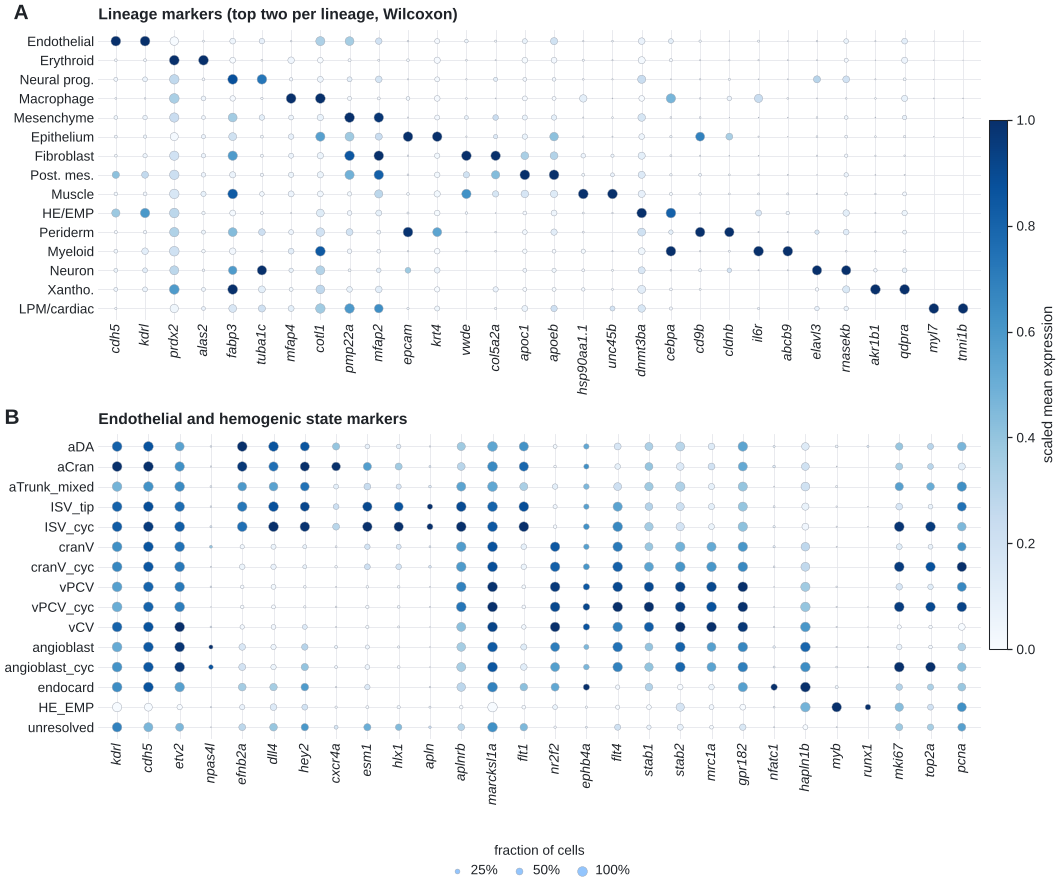

In [35]:
def dotplot(ax, adata, groupby, order, genes, title):
    X = adata[:, genes].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
    lab = adata.obs[groupby].astype(str).values
    mean = np.vstack([X[lab == g].mean(0) for g in order]); frac = np.vstack([(X[lab == g] > 0).mean(0) for g in order])
    z = (mean - mean.min(0)) / np.where(np.ptp(mean, 0) > 0, np.ptp(mean, 0), 1)
    yy, xx = np.meshgrid(range(len(order)), range(len(genes)), indexing='ij')
    sc_ = ax.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 22, c=z.ravel(), cmap='Blues', vmin=0, vmax=1, linewidths=0.2, edgecolors='#9ca3af')
    ax.set_xticks(range(len(genes))); ax.set_xticklabels(genes, rotation=90, style='italic'); ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
    ax.set_xlim(-0.6, len(genes) - 0.4); ax.set_ylim(len(order) - 0.4, -0.6); ax.set_title(title)
    ax.tick_params(length=0); ax.grid(color=GRID, lw=0.4); ax.set_axisbelow(True); [s.set_visible(False) for s in ax.spines.values()]
    return sc_
sc.tl.rank_genes_groups(a, 'lineage', method='wilcoxon', n_genes=60)
lin_order = a.obs.lineage.value_counts().index.tolist(); lin_genes = []
bad = lambda g: g.startswith(('rpl', 'rps', 'mt-', 'hb', 'si:', 'zgc:', 'CABZ', 'CR', 'CU', 'BX', 'AL', 'FO', 'eGFP', 'GFP', 'mCherry')) or '.' in g and g[0].isupper()
for l in lin_order:
    top = [g for g in pd.DataFrame(a.uns['rank_genes_groups']['names'])[l] if not bad(g) and g not in lin_genes][:2]; lin_genes += top
EC_MK = [g for g in ['kdrl', 'cdh5', 'etv2', 'npas4l', 'efnb2a', 'dll4', 'hey2', 'cxcr4a', 'esm1', 'hlx1', 'apln', 'aplnrb', 'marcksl1a', 'flt1',
                     'nr2f2', 'ephb4a', 'flt4', 'stab1', 'stab2', 'mrc1a', 'gpr182', 'nfatc1', 'hapln1b', 'myb', 'runx1', 'mki67', 'top2a', 'pcna']
         if g in e.var_names]
st_order = [s for s in STATE_COL if s in set(e.obs.state.astype(str))]
fig = new_figure(150)
axA, axB = fig.subplots(2, 1, height_ratios=[1, 1.05])
dotplot(axA, a, 'lineage', lin_order, lin_genes, 'Lineage markers (top two per lineage, Wilcoxon)'); panel(axA, 'A')
s_ = dotplot(axB, e, 'state', st_order, EC_MK, 'Endothelial and hemogenic state markers'); panel(axB, 'B')
cb = fig.colorbar(s_, ax=[axA, axB], fraction=0.02, pad=0.01, aspect=30); cb.set_label('scaled mean expression'); cb.outline.set_linewidth(0.5)
for f_ in (0.25, 0.5, 1.0): axB.scatter([], [], s=f_ * 22, c='#93c5fd', edgecolors='#9ca3af', linewidths=0.2, label=f'{f_:.0%}')
axB.legend(title='fraction of cells', loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=3)
save(fig, 'FigS1_markers', outdir='supplementary'); plt.show()

### Figure S2. The ISV_cyc versus ISV_tip difference is a cell-cycle difference

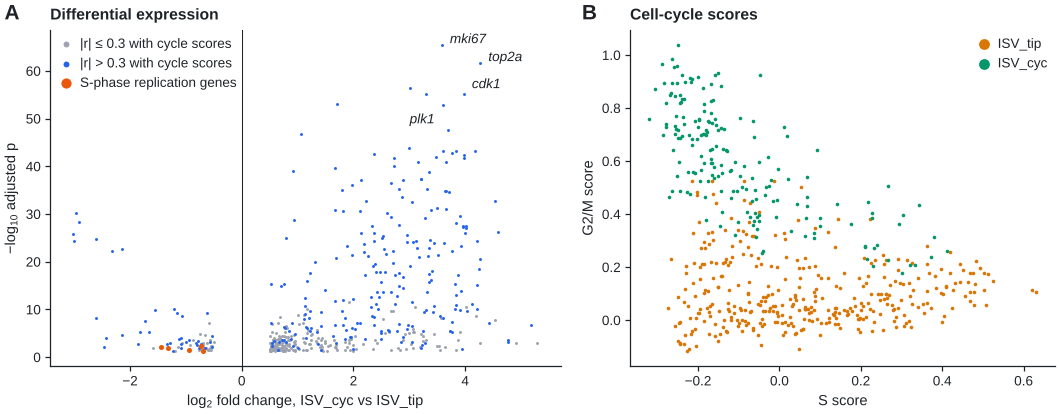

In [36]:
fig = new_figure(70)
axA, axB = fig.subplots(1, 2, width_ratios=[1.2, 1])
D = pd.read_csv('results/TableS_ISVcyc_vs_tip_DE.csv'); D['nlp'] = -np.log10(D.pvals_adj.clip(lower=1e-300)); cyc = D.r_cycle.abs() > 0.3
axA.scatter(D.logfoldchanges[~cyc], D.nlp[~cyc], s=2, color=C['no'], linewidths=0, rasterized=True, label='|r| ≤ 0.3 with cycle scores')
axA.scatter(D.logfoldchanges[cyc], D.nlp[cyc], s=2, color=C['accent'], linewidths=0, rasterized=True, label='|r| > 0.3 with cycle scores')
for g, off in [('mki67', (4, 1)), ('top2a', (4, 1)), ('cdk1', (4, 3)), ('plk1', (-16, -9))]:
    if g in set(D.names):
        r_ = D[D.names == g].iloc[0]; axA.annotate(g, (r_.logfoldchanges, r_.nlp), fontsize=6.5, style='italic', xytext=off, textcoords='offset points')
SPH = D[D.names.isin(['mcm7', 'rfc4', 'pold1', 'fen1', 'gins2'])]
axA.scatter(SPH.logfoldchanges, SPH.nlp, s=6, color=C['orange'], linewidths=0, zorder=4, label='S-phase replication genes')
axA.axvline(0, color=INK, lw=0.5); axA.set_xlabel('log$_2$ fold change, ISV_cyc vs ISV_tip'); axA.set_ylabel('−log$_{10}$ adjusted p')
axA.legend(loc='upper left', markerscale=2, frameon=True, facecolor='white', edgecolor='none', framealpha=1); axA.set_title('Differential expression'); panel(axA, 'A')
iso_ = e.obs[e.obs.state.isin(['ISV_tip', 'ISV_cyc'])]
for s in ['ISV_tip', 'ISV_cyc']:
    d_ = iso_[iso_.state == s]; axB.scatter(d_.S_score, d_.G2M_score, s=3, color=STATE_COL[s], linewidths=0, label=s, rasterized=True)
axB.set_xlabel('S score'); axB.set_ylabel('G2/M score'); axB.legend(markerscale=3, loc='upper right'); axB.set_title('Cell-cycle scores'); panel(axB, 'B')
save(fig, 'FigS2_ISV_DE', outdir='supplementary'); plt.show()

### Figure S3. Calibration of the E-Flux capacity and the U = 100 sensitivity setting

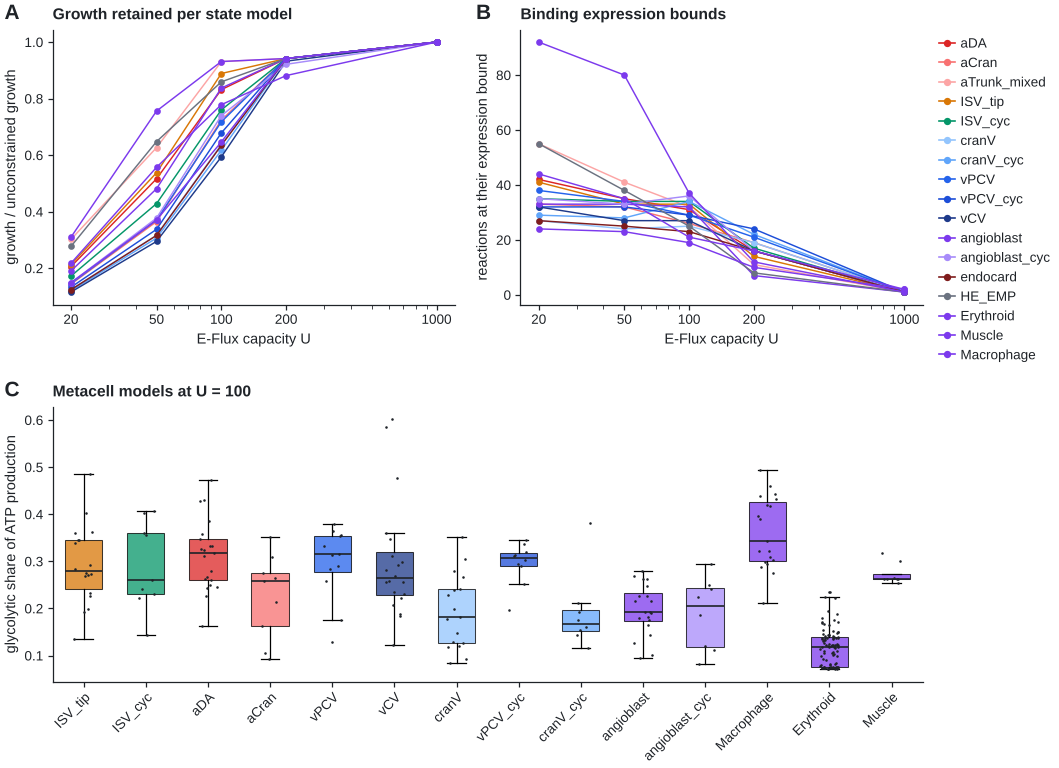

In [37]:
fig = new_figure(130)
gs = fig.add_gridspec(2, 2)
ax = fig.add_subplot(gs[0, 0]); ax2 = fig.add_subplot(gs[0, 1])
sw = SW[SW.setting != 'conventional (U=1000, s/max)']
for g in [x for x in EC_STATES if x in set(sw.group)] + ['Erythroid', 'Muscle', 'Macrophage']:
    d_ = sw[sw.group == g].sort_values('U'); col = STATE_COL.get(g, C['nonec'])
    ax.plot(d_.U, d_.growth_rel, '-o', ms=2.2, lw=0.7, color=col); ax2.plot(d_.U, d_.at_bound, '-o', ms=2.2, lw=0.7, color=col)
for a_ in (ax, ax2): a_.set_xscale('log'); a_.set_xticks([20, 50, 100, 200, 1000]); a_.set_xticklabels(['20', '50', '100', '200', '1000']); a_.set_xlabel('E-Flux capacity U')
ax.set_ylabel('growth / unconstrained growth'); ax.set_title('Growth retained per state model'); panel(ax, 'A')
hd_ = [mpl.lines.Line2D([], [], color=STATE_COL.get(g, C['nonec']), marker='o', ms=2.5, lw=0.8, label=g)
       for g in [x for x in EC_STATES if x in set(sw.group)] + ['Erythroid', 'Muscle', 'Macrophage']]
ax2.set_ylabel('reactions at their expression bound'); ax2.set_title('Binding expression bounds'); panel(ax2, 'B')
ax2.legend(handles=hd_, loc='upper left', bbox_to_anchor=(1.02, 1.0), ncol=1, fontsize=6.5)
ax = fig.add_subplot(gs[1, :]); d100 = MC[MC.U == 100]
grp2 = [g for g in ['ISV_tip', 'ISV_cyc', 'aDA', 'aCran', 'vPCV', 'vCV', 'cranV', 'vPCV_cyc', 'cranV_cyc', 'angioblast', 'angioblast_cyc', 'Macrophage', 'Erythroid', 'Muscle'] if g in set(d100.group)]
data = [d100[d100.group == g].glyc_ATP_frac.dropna() for g in grp2]
bp = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color=INK, lw=0.8), whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6))
for p_, g in zip(bp['boxes'], grp2): p_.set_facecolor(STATE_COL.get(g, C['nonec'])); p_.set_alpha(0.75); p_.set_linewidth(0.5)
for i, dv in enumerate(data): ax.scatter(np.full(len(dv), i + 1) + np.random.default_rng(i).uniform(-0.15, 0.15, len(dv)), dv, s=1.5, color=INK, zorder=3, linewidths=0)
ax.set_xticks(range(1, len(grp2) + 1)); ax.set_xticklabels(grp2, rotation=45, ha='right', rotation_mode='anchor'); ax.set_ylabel('glycolytic share of ATP production')
ax.set_title('Metacell models at U = 100'); panel(ax, 'C')
save(fig, 'FigS3_eflux_calibration', outdir='supplementary'); plt.show()

### Figure S4. Ensemble structure and the three all-lineage calls

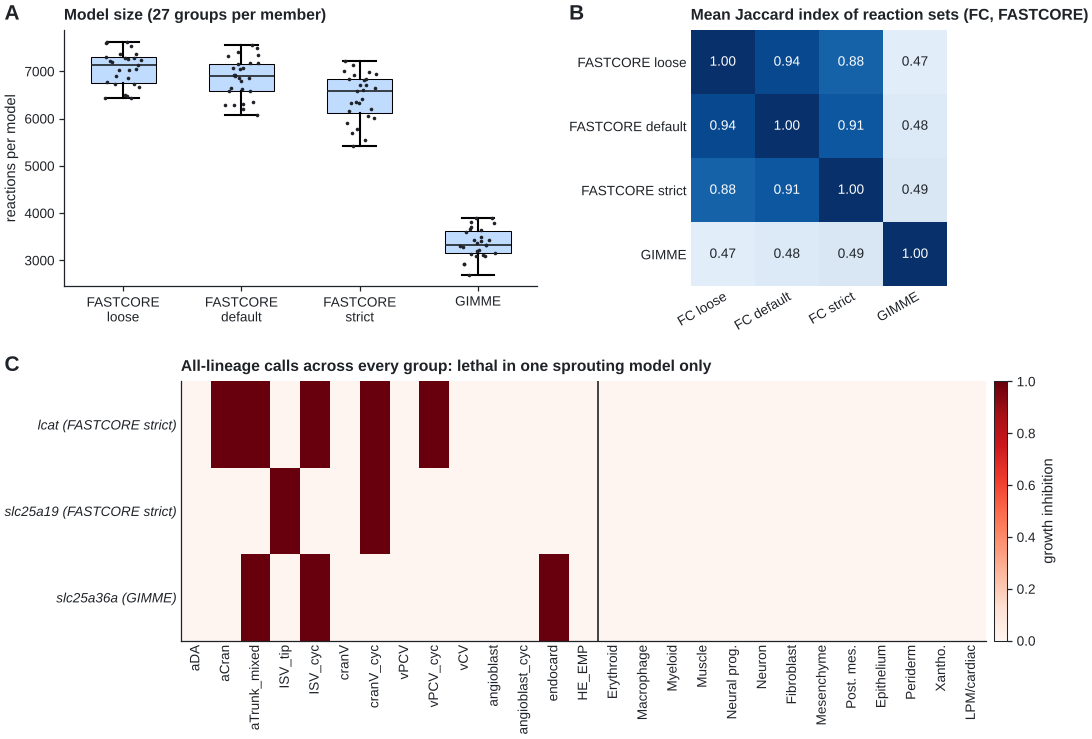

In [38]:
CTX = {k: json.load(open(f"results/ctx_{k.replace('/', '_')}.json")) for k in ENS}
mem = list(ENS); J = pd.DataFrame(np.nan, index=[MEMN[k] for k in mem], columns=[MEMN[k] for k in mem])
for k1, k2 in itertools.product(mem, mem):
    J.loc[MEMN[k1], MEMN[k2]] = np.mean([len(set(CTX[k1][g]) & set(CTX[k2][g])) / len(set(CTX[k1][g]) | set(CTX[k2][g])) for g in CTX[k1]])
fig = new_figure(125)
top, bot = fig.subfigures(2, 1, height_ratios=[1, 1.15])
axA, axB = top.subplots(1, 2, width_ratios=[1, 1])
bpd = [sizes[k].values for k in mem]
bp = axA.boxplot(bpd, widths=0.55, patch_artist=True, medianprops=dict(color=INK, lw=0.8), showfliers=False)
for p_ in bp['boxes']: p_.set_facecolor('#bfdbfe'); p_.set_linewidth(0.5)
for i, dv in enumerate(bpd): axA.scatter(np.full(len(dv), i + 1) + np.random.default_rng(i).uniform(-0.15, 0.15, len(dv)), dv, s=3, color=INK, zorder=3, linewidths=0)
axA.set_xticks(range(1, 5)); axA.set_xticklabels([MEMN[k].replace(' ', '\n') for k in mem]); axA.set_ylabel('reactions per model'); axA.set_title('Model size (27 groups per member)'); panel(axA, 'A')
im = axB.imshow(J.values, cmap='Blues', vmin=0.4, vmax=1)
for i in range(4):
    for j in range(4): axB.text(j, i, f'{J.iloc[i, j]:.2f}', ha='center', va='center', fontsize=6.5, color='white' if J.iloc[i, j] > 0.8 else INK)
axB.set_xticks(range(4)); axB.set_xticklabels(['FC loose', 'FC default', 'FC strict', 'GIMME'], rotation=30, ha='right', rotation_mode='anchor'); axB.set_yticks(range(4)); axB.set_yticklabels(J.index)
axB.tick_params(length=0); [s.set_visible(False) for s in axB.spines.values()]; axB.set_title('Mean Jaccard index of reaction sets (FC, FASTCORE)'); panel(axB, 'B')
axC = bot.subplots(1, 1)
calls_s = [(k, g) for k, (d, _, _) in ENS.items() for g in d.index[d.call_all]]
order_g = [g for g in EC_STATES if g in ENS[mem[0]][1].columns] + NONEC
Hs = pd.DataFrame([ENS[k][1].loc[g, order_g].values for k, g in calls_s], index=[f'{g} ({MEMN[k]})' for k, g in calls_s], columns=order_g)
im2 = axC.imshow(Hs.values, aspect='auto', cmap='Reds', vmin=0, vmax=1)
axC.set_xticks(range(len(order_g))); axC.set_xticklabels(order_g, rotation=90); axC.set_yticks(range(len(Hs))); axC.set_yticklabels(Hs.index)
axC.axvline(len([g for g in EC_STATES if g in order_g]) - 0.5, color=INK, lw=0.8); axC.tick_params(length=0)
for t in axC.get_yticklabels(): t.set_style('italic')
cbar = bot.colorbar(im2, ax=axC, fraction=0.02, pad=0.01); cbar.set_label('growth inhibition'); cbar.outline.set_linewidth(0.5)
axC.set_title('All-lineage calls across every group: lethal in one sprouting model only'); panel(axC, 'C')
save(fig, 'FigS4_ensemble', outdir='supplementary'); plt.show()

In [39]:
# ---- Supplementary data workbook (Data S1)
with pd.ExcelWriter('supplementary/FluxSprout_Supplementary_Data.xlsx') as xw:
    pd.DataFrame({'sheet': ['S1a', 'S1b', 'S1c', 'S2', 'S3', 'S4', 'S5', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14'],
                  'content': ['QC per library', 'cells per lineage', 'cells per state', 'medium and exchange bounds', 'groups, compartments, metacells, model sizes',
                              'marker panels and cell-cycle genes', 'model quality metrics', 'ISV_cyc vs ISV_tip differential expression',
                              'ISV_cyc vs ISV_tip pathway scores, raw and adjusted', 'marker-level claim tests', 'metacell flux-level tests',
                              'metacell flux read-outs', 'E-Flux capacity sweep per group', 'limiting nutrient per objective', 'OXPHOS factorial',
                              'loop-capable reactions', 'knockout screen, four ensemble members (inhibition per group)', 'candidate robustness',
                              'mechanism of all-lineage calls', 'knockout calls across media', 'Table 6 recomputed']}).to_excel(xw, sheet_name='README', index=False)
    ts1a.to_excel(xw, sheet_name='S1a_QC'); ts1b.to_excel(xw, sheet_name='S1b_lineages', index=False); ts1c.to_excel(xw, sheet_name='S1c_states', index=False)
    TS2.to_excel(xw, sheet_name='S2_medium', index=False); TS3.to_excel(xw, sheet_name='S3_groups', index=False); TS4.to_excel(xw, sheet_name='S4_panels', index=False); TS5.to_excel(xw, sheet_name='S5_quality')
    for nm, fn in [('D1_ISV_DE', 'TableS_ISVcyc_vs_tip_DE.csv'), ('D2_ISV_pathways', 'TableS_ISVcyc_vs_tip_pathways.csv'), ('D3_claims_marker', 'TableS_claims_marker_level.csv'),
                   ('D4_flux_tests', 'TableS_flux_level_metacell_tests.csv'), ('D5_metacell_readouts', 'eflux_metacells.csv'), ('D6_eflux_sweep', 'eflux_sweep_groups.csv'),
                   ('D7_limiting_nutrient', 'TableS_objective_limiting_nutrient.csv'), ('D8_oxphos_factorial', 'oxphos_factorial.csv'), ('D9_loop_reactions', 'tic_reactions.csv'),
                   ('D11_robustness', 'TableS_candidate_robustness.csv'), ('D12_mechanism', 'TableS_mechanism_rescue.csv'), ('D13_media', 'ko_media_candidates.csv'),
                   ('D14_table6', 'Table6_recomputed.csv')]:
        pd.read_csv(f'results/{fn}').to_excel(xw, sheet_name=nm, index=False)
    for k in mem:
        ENS[k][1].to_excel(xw, sheet_name=f"D10_KO_{k.replace('/', '_')}"[:31])
print('supplementary files:', sorted(os.listdir('supplementary')))

supplementary files: ['FigS1_markers.pdf', 'FigS1_markers.png', 'FigS2_ISV_DE.pdf', 'FigS2_ISV_DE.png', 'FigS3_eflux_calibration.pdf', 'FigS3_eflux_calibration.png', 'FigS4_ensemble.pdf', 'FigS4_ensemble.png', 'FluxSprout_Supplementary_Data.xlsx', 'FluxSprout_Supplementary_Information.docx', 'TableS1a_qc_per_library.csv', 'TableS1b_cells_per_lineage.csv', 'TableS1c_cells_per_state.csv', 'TableS2_medium.csv', 'TableS3_groups.csv', 'TableS4_panels.csv', 'TableS5_model_quality.csv']
